<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color:RGB(46,125,50);
            border-radius:8px;
            padding:18px;
            margin-top:15px;
            color:white;">

<h3 style="margin-top:0;">Organisation des étapes d'analyse et de préparation des données</h3>

Ce projet répond à <b>deux objectifs distincts et complémentaires</b> : d'une part, réaliser les analyses nécessaires à l'étude des données disponibles et, d'autre part, construire un <b>pipeline de préparation des données</b> permettant d'obtenir, en fin de traitement, des fichiers propres, correctement typés et prêts à être exploités.

Dans un premier temps, les analyses sont réalisées à partir des données nécessaires aux indicateurs étudiés. Les variables utilisées pour les calculs de <b>chiffre d'affaires, quantités vendues, stock, marge et corrélations</b> sont issues principalement des données ERP et sont déjà exploitables pour ces calculs. Il n'est donc pas nécessaire d'effectuer l'intégralité du nettoyage des autres colonnes avant de réaliser ces analyses.

Dans un second temps, le projet se concentre sur la <b>préparation et la fiabilisation des trois sources de données</b> : nettoyage des dates, des textes, des valeurs booléennes et des types de données, puis réalisation du rapprochement final des fichiers. Cette étape aboutit à une <b>table finale propre et structurée</b>, destinée à constituer le résultat du pipeline de traitement.

Ainsi, l'ordre des opérations observé dans le notebook est <b>volontaire</b> et correspond aux deux objectifs du projet : les analyses portent sur les variables nécessaires à l'étude, tandis que le nettoyage complet et le typage de l'ensemble des données constituent une étape distincte de <b>construction du pipeline de données</b>.

Afin de garantir la traçabilité du traitement, la version finale des données nettoyées est néanmoins conservée séparément et les étapes de préparation sont documentées. Les résultats analytiques présentés précédemment ne sont pas recalculés après cette étape, car les variables utilisées pour ces analyses étaient déjà correctement exploitables dans les sources concernées.

</div>


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [6]:
#Importation des librairies
import pandas as pd

import seaborn as sns

import scipy.stats as sc

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

import squarify

pd.set_option('display.float_format', '{:.2f}'.format)

In [7]:
#Importation de la librairie plotly express
import plotly.express as px

In [8]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

Attention ! Pensez à bien modifier le chemin :

In [11]:
import os

# Modifiez le chemin vers votre dossier contenant le notebook et les fichiers csv.
os.chdir(r".....")

# Pour vérifier
print("Nouveau répertoire :", os.getcwd())

Nouveau répertoire : C:\Users\victo\OneDrive\Dokumente\Projet OC\OCP6


In [12]:
try:
    erp = pd.read_csv('erp.csv')
    web = pd.read_csv('web.csv')
    liaison = pd.read_csv('liaison.csv')
    print("✅ Les fichiers ont bien été chargés.")
except Exception as e:
    print("❌ Erreur lors du chargement :", e)

✅ Les fichiers ont bien été chargés.


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [15]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [16]:
#Consulter le nombre de colonnes
erp.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status',
       'purchase_price'],
      dtype='object')

In [17]:
# Nature des données dans chacune des colonnes
erp.dtypes

product_id          int64
onsale_web          int64
price             float64
stock_quantity      int64
stock_status       object
purchase_price    float64
dtype: object

In [18]:
#Le nombre de valeurs présentes dans chacune des colonnes
erp.count(axis=0, numeric_only=False)

product_id        825
onsale_web        825
price             825
stock_quantity    825
stock_status      825
purchase_price    825
dtype: int64

In [19]:
#Afficher les 5 premières lignes de la table
erp.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.20,16,instock,12.88
1,3849,1,34.30,10,instock,17.54
2,3850,1,20.80,0,outofstock,10.64
3,4032,1,14.10,26,instock,6.92
4,4039,1,46.00,3,outofstock,23.77


In [20]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
list_product_id = []

for product_id in erp['product_id']:
   if product_id is not None:
     list_product_id.append(product_id)
     nb_id = list_product_id.count(product_id)
     if nb_id > 1:
        print("au moins un identifiant n'est pas unique")
        break
else:
    print("les product_id sont uniques et non nuls")

les product_id sont uniques et non nuls


In [21]:
#Afficher les valeurs distinctes de la colonne stock_status
print(erp['stock_status'].unique())



['instock' 'outofstock']


In [22]:
#À quelle(s) autre(s) colonne(s) sont-elles liées ?

Logiquement, stock_status devrait être relié à stock_quantity. Mais aussi éventuelemnt à onsale_web.

In [24]:
#On commence par renommer la colonne et la transformer en booléen
erp_nettoye = erp.rename(columns={'stock_status': 'in_stock'})

erp_nettoye['in_stock'] = erp_nettoye['in_stock'].map({"instock": True, "outofstock": False})
print(erp_nettoye['in_stock'].unique())

[ True False]


Ok, maintenant, on va tester les liens logiques entre les variables booléennes et les autres variables :

1 : si in_stock est True alors stock_quantity > 0

2 : si onsale_web est True alors in stock true et stock quantity > 0

In [26]:
# Identifier les incohérences
incoherences = (
    (erp_nettoye['in_stock'] == True)
    & (erp_nettoye['stock_quantity'] < 1)
)

# Vérifier s'il existe une incohérence
if incoherences.any():
    i = incoherences.idxmax()
    print(f"Incohérence dans le fichier à la ligne {i}")
else:
    print("Le fichier est cohérent dans la relation entre stock_quantity et in_stock")

Incohérence dans le fichier à la ligne 398


On a trouvé une incohérence. Maintenant on va vérifier pour toutes les lignes :

In [28]:
# Identifier les lignes incohérentes
incoherences = (
    erp_nettoye['in_stock']
    & (erp_nettoye['stock_quantity'] < 1)
)

# Afficher les lignes incohérentes
erp_nettoye[incoherences].apply(
    lambda row: print(
        f"Ligne incohérente index={row.name}: {row.to_dict()}"
    ),
    axis=1
)

Ligne incohérente index=398: {'product_id': 4885, 'onsale_web': 1, 'price': 18.7, 'stock_quantity': 0, 'in_stock': True, 'purchase_price': 9.66}


398    None
dtype: object

Une seule ligne incohérente, on va changer la valeur du booléen pour conserver la relation logique

In [30]:
# Corriger les incohérences entre in_stock et stock_quantity
erp_nettoye.loc[
    erp_nettoye['in_stock'] & (erp_nettoye['stock_quantity'] < 1),
    'in_stock'
] = False

Et vice-versa :

In [32]:
# Corriger les incohérences entre in_stock et stock_quantity
erp_nettoye.loc[
    (~erp_nettoye['in_stock']) & (erp_nettoye['stock_quantity'] > 0),
    'in_stock'
] = True

Vérification :

In [34]:
incoherences = (
    (erp_nettoye['in_stock'] == True) & (erp_nettoye['stock_quantity'] < 1)
) | (
    (erp_nettoye['in_stock'] == False) & (erp_nettoye['stock_quantity'] > 0)
)

if incoherences.any():
    i = incoherences.idxmax()
    print(f"Incohérence dans le fichier à la ligne {i}")
else:
    print("Le fichier est cohérent dans la relation entre stock_quantity et in_stock")

Le fichier est cohérent dans la relation entre stock_quantity et in_stock


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

On va commencer par vérifier s'il y a des valeurs nulles :

In [38]:
valeurs_nulles = erp_nettoye['price'].isna()

if valeurs_nulles.any():
    i = valeurs_nulles.idxmax()
    print(f"Valeur nulle trouvée à la ligne {i}")
else:
    print("Tout produit a un prix")

Tout produit a un prix


On va faire le reste en une seule instruction :

<Axes: xlabel='price', ylabel='Count'>

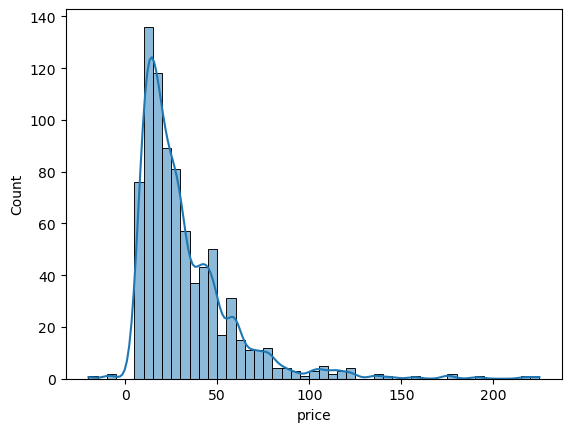

In [40]:
sns.histplot(erp_nettoye, x='price', binwidth=5, kde=True, kde_kws={'bw_adjust': 0.5})

Courbe assymétrique dégressive, logique pour une distribution de prix (beaucoup de produits bons marchés, quelques produits très chers).

Par contre, valeurs négatives = impossible. On supposera une faute de frappe. On va les refaire passer en positif.

Pas de valeurs aberrantes évidentes. Des bouteilles de vin entre 150 et 250 ça existe. 

In [42]:
erp_nettoye['price'] = erp_nettoye['price'].abs()

if (erp_nettoye['price'] < 0).any():
    print("Le nettoyage n'a pas fonctionné")
else:
    print("Le nettoyage a fonctionné")

Le nettoyage a fonctionné


<Axes: xlabel='price', ylabel='Count'>

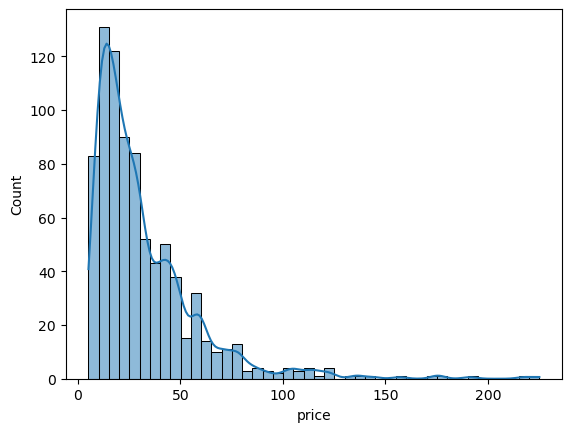

In [43]:
sns.histplot(erp_nettoye, x='price', binwidth=5, kde=True, kde_kws={'bw_adjust': 0.5})

Prix : OK.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

On va commencer par vérifier s'il y a des valeurs nulles :

In [47]:
valeurs_nulles = erp_nettoye['stock_quantity'].isna()

if valeurs_nulles.any():
    i = valeurs_nulles.idxmax()
    print(f"Valeur nulle trouvée à la ligne {i}")
else:
    print("Tout produit a un stock")

Tout produit a un stock


<Axes: xlabel='stock_quantity', ylabel='Count'>

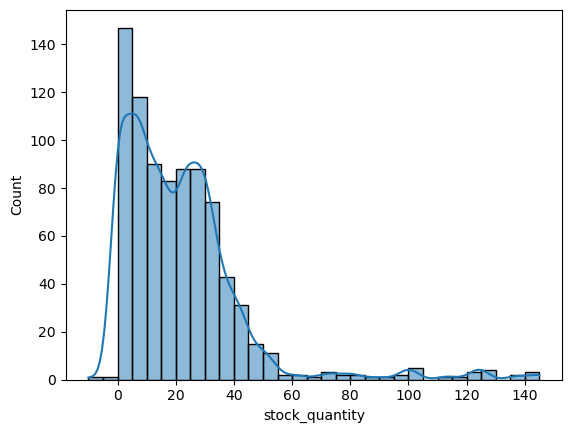

In [48]:
sns.histplot(erp_nettoye, x='stock_quantity', binwidth=5, kde=True, kde_kws={'bw_adjust': 0.5})

Bon, on a des stock_quantity < 0 ce qui est évidement impossible. On va utiliser clip pour définir 0 comme le minimum. Cela nous permet de rester cohérent avec stock_status. 

In [50]:
erp_nettoye['stock_quantity'] = erp_nettoye['stock_quantity'].clip(lower=0)

<Axes: xlabel='stock_quantity', ylabel='Count'>

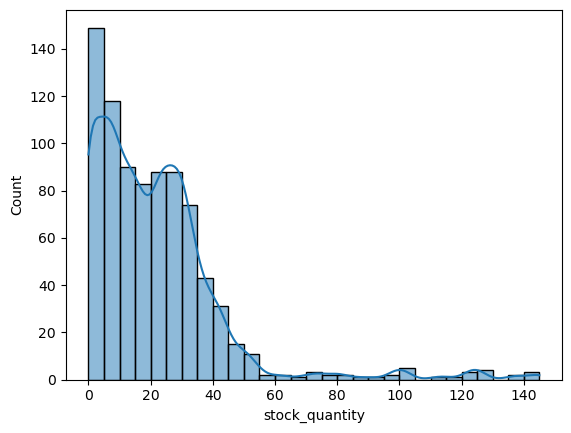

In [51]:
sns.histplot(erp_nettoye, x='stock_quantity', binwidth=5, kde=True, kde_kws={'bw_adjust': 0.5})

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [53]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
print(erp_nettoye['onsale_web'].unique())

[1 0]


1 = True ; 0 = False.

In [55]:
erp_nettoye['onsale_web'] = erp_nettoye['onsale_web'].map({0: False, 1: True})
print(erp_nettoye['onsale_web'].unique())

[ True False]


Pour le plaisir, on testera la relation entre stock_quantity et onsale_web, logiquement si c'est en vente sur le web, on devrait avoir des éléments en stock :


In [57]:
# Identifier les incohérences
incoherences = (
    (erp_nettoye['onsale_web'] == True) & (erp_nettoye['stock_quantity'] < 1)
) | (erp_nettoye['in_stock'] == False)

# Vérifier s'il existe au moins une incohérence
if incoherences.any():
    i = incoherences.idxmax()
    print("Incohérence dans le fichier à la ligne", i)
else:
    print("Le fichier est cohérent dans la relation entre onsale_web, stock_quantity et in_stock")

Incohérence dans le fichier à la ligne 2


On va vérifier pour toutes les lignes : 

In [59]:
# Identifier les lignes incohérentes
incoherences = (
    erp_nettoye['onsale_web']
    & (
        (erp_nettoye['stock_quantity'] < 1)
        | (~erp_nettoye['in_stock'])
    )
)

# Afficher les lignes incohérentes
for i, row in erp_nettoye[incoherences].iterrows():
    print(f"Ligne incohérente index={i}: {row.to_dict()}")

Ligne incohérente index=2: {'product_id': 3850, 'onsale_web': True, 'price': 20.8, 'stock_quantity': 0, 'in_stock': False, 'purchase_price': 10.64}
Ligne incohérente index=8: {'product_id': 4043, 'onsale_web': True, 'price': 60.0, 'stock_quantity': 0, 'in_stock': False, 'purchase_price': 29.45}
Ligne incohérente index=11: {'product_id': 4047, 'onsale_web': True, 'price': 18.3, 'stock_quantity': 0, 'in_stock': False, 'purchase_price': 9.93}
Ligne incohérente index=15: {'product_id': 4051, 'onsale_web': True, 'price': 7.7, 'stock_quantity': 0, 'in_stock': False, 'purchase_price': 4.14}
Ligne incohérente index=16: {'product_id': 4052, 'onsale_web': True, 'price': 33.7, 'stock_quantity': 0, 'in_stock': False, 'purchase_price': 18.11}
Ligne incohérente index=28: {'product_id': 4065, 'onsale_web': True, 'price': 19.5, 'stock_quantity': 0, 'in_stock': False, 'purchase_price': 9.67}
Ligne incohérente index=42: {'product_id': 4079, 'onsale_web': True, 'price': 37.0, 'stock_quantity': 0, 'in_sto

Trop d'incohérences, on_sale_web peut être True alors que le stock est à 0 ? Dans un contexte pro, il faudrait en discuter avec la boutique. 

Dans le cadre de cet exercice, on va considérer que les variables ne sont finalement pas corrélées. 

In [61]:
#Quelles sont les colonnes à conserver selon vous?
erp_nettoye.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'in_stock',
       'purchase_price'],
      dtype='object')

Toutes !

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

On va commencer par vérifier s'il y a des valeurs nulles :

In [65]:
valeurs_nulles = erp_nettoye['stock_quantity'].isna()

if valeurs_nulles.any():
    i = valeurs_nulles.idxmax()
    print(f"Valeur nulle trouvée à la ligne {i}")
else:
    print("Tout produit a un prix d'achat")

Tout produit a un prix d'achat


<Axes: xlabel='purchase_price', ylabel='Count'>

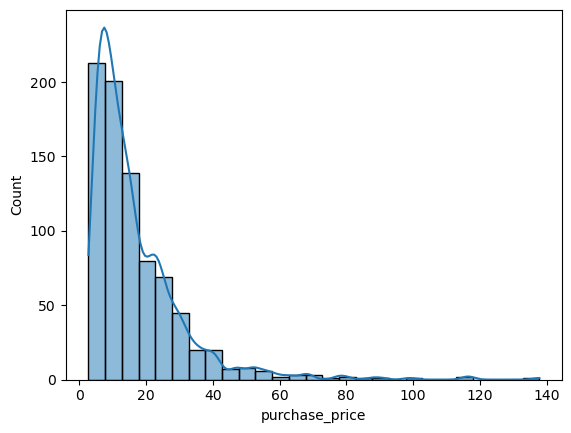

In [66]:
sns.histplot(erp_nettoye, x='purchase_price', binwidth=5, kde=True, kde_kws={'bw_adjust': 0.5})

Ok, in fine ça semble logique. Pas de purchase_price null, pas de valeurs négatives et maximum inférieur au prix d'achat.

Pour le plaisir du jeu, on va tester la corrélation entre prix de vente et d'achat pour voir la robustesse du dataframe.

In [69]:
from scipy.stats import pearsonr

corr, p_value = pearsonr(erp_nettoye['price'], erp_nettoye['purchase_price'])
print("Corrélation Pearson :", corr)
print("p-value :", p_value)

if p_value < 0.05:
   print("Corrélation significative")
else :
    print("Corrélation non significative")

Corrélation Pearson : 0.9693704304344265
p-value : 0.0
Corrélation significative


In [70]:
from scipy.stats import spearmanr

# Garder uniquement les observations complètes
df_spearman = erp_nettoye[['price', 'purchase_price']].dropna()

# Calcul de la corrélation de Spearman
corr, p_value = spearmanr(
    df_spearman['price'],
    df_spearman['purchase_price']
)

print("Corrélation de Spearman :", corr)
print("p-value :", p_value)

if p_value < 0.05:
    print("La corrélation est statistiquement significative.")
else:
    print("La corrélation n'est pas statistiquement significative.")

Corrélation de Spearman : 0.9918108988383453
p-value : 0.0
La corrélation est statistiquement significative.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [72]:
#Dimension du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(web.shape[0]))
print("Le tableau comporte {} colonne(s)".format(web.shape[1]))

Le tableau comporte 1513 observation(s) ou article(s)
Le tableau comporte 29 colonne(s)


In [73]:
#Nombre d'observations
web.count(axis=0, numeric_only=False)

sku                      1428
virtual                  1513
downloadable             1513
rating_count             1513
average_rating           1430
total_sales              1430
tax_status                716
tax_class                   0
post_author              1430
post_date                1430
post_date_gmt            1430
post_content                0
product_type             1429
post_title               1430
post_excerpt              716
post_status              1430
comment_status           1430
ping_status              1430
post_password               0
post_name                1430
post_modified            1430
post_modified_gmt        1430
post_content_filtered       0
post_parent              1430
guid                     1430
menu_order               1430
post_type                1430
post_mime_type            714
comment_count            1430
dtype: int64

In [74]:
#Consulter le nombre de colonnes
web.columns

Index(['sku', 'virtual', 'downloadable', 'rating_count', 'average_rating',
       'total_sales', 'tax_status', 'tax_class', 'post_author', 'post_date',
       'post_date_gmt', 'post_content', 'product_type', 'post_title',
       'post_excerpt', 'post_status', 'comment_status', 'ping_status',
       'post_password', 'post_name', 'post_modified', 'post_modified_gmt',
       'post_content_filtered', 'post_parent', 'guid', 'menu_order',
       'post_type', 'post_mime_type', 'comment_count'],
      dtype='object')

In [75]:
#La nature des données dans chacune des colonnes
web.dtypes

sku                       object
virtual                    int64
downloadable               int64
rating_count               int64
average_rating           float64
total_sales              float64
tax_status                object
tax_class                float64
post_author              float64
post_date                 object
post_date_gmt             object
post_content             float64
product_type              object
post_title                object
post_excerpt              object
post_status               object
comment_status            object
ping_status               object
post_password            float64
post_name                 object
post_modified             object
post_modified_gmt         object
post_content_filtered    float64
post_parent              float64
guid                      object
menu_order               float64
post_type                 object
post_mime_type            object
comment_count            float64
dtype: object

In [76]:
#Selon vous, quelles sont les colonnes à conserver ?
for col in web.columns:
       if web[col].nunique() <= 1:
         print(col, web[col].unique())
    

virtual [0]
downloadable [0]
rating_count [0]
average_rating [ 0. nan]
tax_status [nan 'taxable']
tax_class [nan]
post_content [nan]
post_status ['publish' nan]
comment_status ['closed' nan]
ping_status ['closed' nan]
post_password [nan]
post_content_filtered [nan]
post_parent [ 0. nan]
menu_order [ 0. nan]
post_mime_type ['image/jpeg' nan]
comment_count [ 0. nan]


Donc là, on voit qu'il y a beaucoup de colonnes avec une seule et unique valeur. Et certaines colonnes avec une valeur et un nan. Pour ces dernières, on va supposer que c'est des booléens (si rempli, True, sinon False) et qu'elles contiennent des informations exploitables. 

Pour les autres, clairement l'information est nulle. On va les supprimer. 

In [78]:
#Selon vous, quelles sont les colonnes à conserver ?
for col in web.columns.tolist():
    uniques = web[col].unique()  
    if len(uniques) == 1:              
        print("Colonne supprimée :", col, "→ valeur :", uniques)
        web.drop(columns=[col], inplace=True)

Colonne supprimée : virtual → valeur : [0]
Colonne supprimée : downloadable → valeur : [0]
Colonne supprimée : rating_count → valeur : [0]
Colonne supprimée : tax_class → valeur : [nan]
Colonne supprimée : post_content → valeur : [nan]
Colonne supprimée : post_password → valeur : [nan]
Colonne supprimée : post_content_filtered → valeur : [nan]


In [79]:
# Visualisation des valeurs de la colonne sku
# Identification des lignes dont le SKU est manquant

lignes_sans_sku = web[web['sku'].isna()]

print(f"Nombre total de lignes sans SKU : {len(lignes_sans_sku)}")
print("\nLes 20 premières lignes concernées :")

print(lignes_sans_sku[['sku']].head(20))



Nombre total de lignes sans SKU : 85

Les 20 premières lignes concernées :
     sku
8    NaN
20   NaN
30   NaN
37   NaN
41   NaN
47   NaN
55   NaN
75   NaN
94   NaN
127  NaN
130  NaN
136  NaN
153  NaN
162  NaN
169  NaN
184  NaN
198  NaN
199  NaN
244  NaN
264  NaN


Là, on voit que les skus vides correspondent principalement à des lignes, plutôt vides....

In [81]:
# Identification des codes articles ne respectant pas la règle de codification
# Les SKU doivent être constitués uniquement de chiffres entiers

sku_non_entiers = web[
    web['sku'].notna() &
    ~web['sku'].astype(str).str.fullmatch(r'\d+')
]

print(f"Nombre total de SKU non conformes : {len(sku_non_entiers)}")
print("\nLes 20 premiers SKU non conformes :")

print(
    sku_non_entiers[
        ['post_title', 'sku']
    ].head(20).to_string(index=False)
)


Nombre total de SKU non conformes : 4

Les 20 premiers SKU non conformes :
                                  post_title                 sku
Clos du Mont-Olivet Châteauneuf-du-Pape 2007             13127-1
                           Bon cadeau de 25€ bon-cadeau-25-euros
Clos du Mont-Olivet Châteauneuf-du-Pape 2007             13127-1
                           Bon cadeau de 25€ bon-cadeau-25-euros


Ils sont deux ! Ce n'est pas la peine des les supprimer, si on merge les fichiers avec un inner join, de toutes manières, ça ne conservera que les correspondances.

On va supprimer les lignes où tout est vide :

In [84]:
web_nettoye = web.copy()

rows_to_delete = []

for i, row in web_nettoye.iterrows():
    empty = True
    for col in web.columns:
        if col != 'sku':  # on ignore sku, déjà NaN
            if not (pd.isna(row[col]) or row[col] == 0):
                empty = False
    
    # si toute la ligne est vide marquer pour suppression
    if empty:
        rows_to_delete.append(i)

# supprimer les lignes trouvées
web_nettoye = web_nettoye.drop(index=rows_to_delete)

In [85]:
#Le nombre de valeurs présentes dans chacune des colonnes
web_nettoye.count(axis=0, numeric_only=False)

sku                  1428
average_rating       1430
total_sales          1430
tax_status            716
post_author          1430
post_date            1430
post_date_gmt        1430
product_type         1429
post_title           1430
post_excerpt          716
post_status          1430
comment_status       1430
ping_status          1430
post_name            1430
post_modified        1430
post_modified_gmt    1430
post_parent          1430
guid                 1430
menu_order           1430
post_type            1430
post_mime_type        714
comment_count        1430
dtype: int64

On a fait le gros du travail, maintenant il faut voir quelles sont les lignes qui restent sans sku :

In [87]:
lignes_sans_sku = web_nettoye['sku'].isna()

print(web_nettoye[lignes_sans_sku])

      sku  average_rating  total_sales tax_status  post_author  \
1084  NaN            0.00       -56.00    taxable         2.00   
1087  NaN            0.00       -17.00    taxable         2.00   

                post_date        post_date_gmt product_type  \
1084  2018-08-08 11:23:43  2018-08-08 09:23:43          Vin   
1087  2018-07-31 12:07:23  2018-07-31 10:07:23          Vin   

                                           post_title  \
1084  Pierre Jean Villa Condrieu Jardin Suspendu 2018   
1087       Pierre Jean Villa Côte Rôtie Fongeant 2017   

                                           post_excerpt  ... ping_status  \
1084  <span id="u1194-83">Le nez séduit par ses parf...  ...      closed   
1087  Fongeant 2017 explose sur un fruit brillant, p...  ...      closed   

                                       post_name        post_modified  \
1084    pierre-jean-villa-condrieu-suspendu-2018  2019-11-02 13:24:01   
1087  pierre-jean-villa-cote-rotie-fongeant-2017  2019-11-02 13:

Là on a deux total sales aberrants, -17 et -56. Dans les deux cas, on a pas de rating... les commentaires sont fermés etc...

On va supposé qu'ils ne sont plus à la vente et les supprimer :

In [89]:
web_nettoye = web_nettoye.dropna(subset=['sku'])

In [90]:
#Le nombre de valeurs présentes dans chacune des colonnes
web_nettoye.count(axis=0, numeric_only=False)

sku                  1428
average_rating       1428
total_sales          1428
tax_status            714
post_author          1428
post_date            1428
post_date_gmt        1428
product_type         1427
post_title           1428
post_excerpt          714
post_status          1428
comment_status       1428
ping_status          1428
post_name            1428
post_modified        1428
post_modified_gmt    1428
post_parent          1428
guid                 1428
menu_order           1428
post_type            1428
post_mime_type        714
comment_count        1428
dtype: int64

On va quand même regarder les total_sales pour voir si il n y a pas de valeurs aberrantes :

<Axes: xlabel='total_sales', ylabel='Count'>

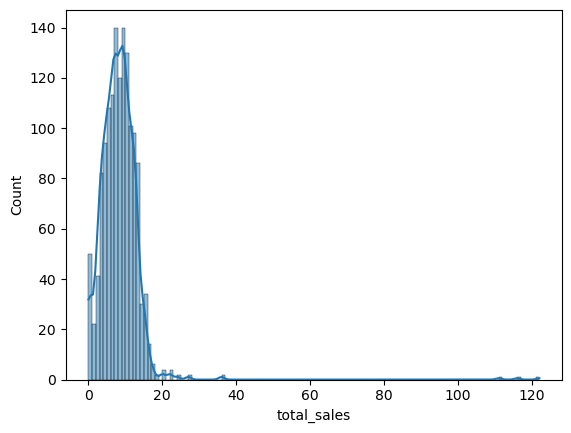

In [92]:
sns.histplot(web_nettoye, x='total_sales', binwidth=1, kde=True, kde_kws={'bw_adjust': 0.5})

C'est bon pour cette partie !

In [94]:
# Vérification de l'unicité des SKU

# Identification des SKU présents plusieurs fois
sku_doublons = web_nettoye[
    web_nettoye['sku'].duplicated(keep=False)
]

# Nombre de SKU concernés par un doublon
nb_doublons = sku_doublons['sku'].nunique()

print(f"Nombre de SKU en doublon : {nb_doublons}")

# Affichage des 20 premiers SKU en doublon
print("\nLes 20 premiers SKU en doublon :")

print(
    sku_doublons[
        ['post_title', 'sku']
    ]
    .sort_values('sku')
    .head(20)
)



Nombre de SKU en doublon : 714

Les 20 premiers SKU en doublon :
                                             post_title    sku
668                   Darnley's London Dry Gin Original  10014
1030                  Darnley's London Dry Gin Original  10014
887   Alphonse Mellot Sancerre Rouge Génération XIX ...  10459
748   Alphonse Mellot Sancerre Rouge Génération XIX ...  10459
802   Albert Mann Pinot Gris Vendanges Tardives Alte...  10775
1317  Albert Mann Pinot Gris Vendanges Tardives Alte...  10775
520   Thierry Germain Saumur-Champigny Outre Terre 2013  10814
860   Thierry Germain Saumur-Champigny Outre Terre 2013  10814
1322  Alphonse Mellot Sancerre Rouge En Grands Champ...  11049
408   Alphonse Mellot Sancerre Rouge En Grands Champ...  11049
1314  Champagne Larmandier-Bernier Terre de Vertus P...  11225
1019  Champagne Larmandier-Bernier Terre de Vertus P...  11225
175             Huile d'Olive Extra Vierge Planeta 50cl  11258
1347            Huile d'Olive Extra Vierge Planeta 50

Oui, il y a des doublons !!

On va voir si les lignes sont égales !!

In [96]:
# Sélectionner uniquement les lignes dont le SKU est en doublon
web_doublons = web_nettoye[
    web_nettoye['sku'].duplicated(keep=False)
].copy()

# Vérifier si les doublons sont vrais ou faux
resultats_doublons = []

for sku_value, group in web_doublons.groupby('sku'):
    
    # Vérifier si toutes les colonnes sauf 'sku' sont identiques
    vrai_doublon = (
        group.drop(columns='sku')
        .nunique(dropna=False)
        .le(1)
        .all()
    )
    
    resultats_doublons.append({
        'sku': sku_value,
        'type': 'Vrai doublon' if vrai_doublon else 'Faux doublon',
        'lignes': list(group.index)
    })

# Transformer les résultats en DataFrame
resultats_doublons = pd.DataFrame(resultats_doublons)

# Afficher uniquement les 20 premiers résultats
print("Les 20 premiers résultats de l'analyse des doublons :")
print(resultats_doublons.head(20).to_string(index=False))

Les 20 premiers résultats de l'analyse des doublons :
  sku         type       lignes
10014 Faux doublon  [668, 1030]
10459 Faux doublon   [748, 887]
10775 Faux doublon  [802, 1317]
10814 Faux doublon   [520, 860]
11049 Faux doublon  [408, 1322]
11225 Faux doublon [1019, 1314]
11258 Faux doublon  [175, 1347]
11277 Faux doublon   [243, 597]
11467 Faux doublon   [611, 950]
11585 Faux doublon  [613, 1297]
11586 Faux doublon    [16, 197]
11587 Faux doublon    [23, 851]
11601 Faux doublon   [527, 871]
11602 Faux doublon   [122, 614]
11641 Faux doublon   [559, 676]
11668 Faux doublon [1241, 1492]
11669 Faux doublon [1202, 1207]
11736 Faux doublon  [540, 1369]
11847 Faux doublon [1242, 1461]
11849 Faux doublon  [276, 1016]


Ah bah ça alors, ce n'est que des faux doublons !

On va regarder quelles sont les colonnes qui posent problèmes :

In [99]:
# Analyse des différences entre les lignes ayant un même SKU

resultats = []

# Limiter l'affichage aux 20 premiers SKU en doublon
for sku, group in web_doublons.groupby('sku'):
    
    # Retirer la colonne SKU pour comparer les autres colonnes
    g = group.drop(columns='sku')
    
    # Identifier les colonnes contenant plusieurs valeurs différentes
    colonnes_diff = g.columns[g.nunique(dropna=False) > 1].tolist()
    
    resultats.append({
        'sku': sku,
        'colonnes_diff': colonnes_diff
    })

# Afficher les 20 premiers résultats
for resultat in resultats[:20]:
    print(f"\nSKU {resultat['sku']} — colonnes différentes : {resultat['colonnes_diff']}")
    
    if resultat['colonnes_diff']:
        print(
            web_doublons[
                web_doublons['sku'] == resultat['sku']
            ][resultat['colonnes_diff']]
        )
    else:
        print(" -> Toutes les colonnes sont identiques (vrai doublon)")



SKU 10014 — colonnes différentes : ['tax_status', 'post_excerpt', 'guid', 'post_type', 'post_mime_type']
     tax_status                                       post_excerpt  \
668     taxable  <span title="">Un gin léger, floral et aromati...   
1030        NaN                                                NaN   

                                                   guid   post_type  \
668   https://www.bottle-neck.fr/?post_type=product&...     product   
1030  https://www.bottle-neck.fr/wp-content/uploads/...  attachment   

     post_mime_type  
668             NaN  
1030     image/jpeg  

SKU 10459 — colonnes différentes : ['tax_status', 'post_excerpt', 'guid', 'post_type', 'post_mime_type']
    tax_status                                       post_excerpt  \
748    taxable  Robe d'un superbe rubis, dense et profond - As...   
887        NaN                                                NaN   

                                                  guid   post_type  \
748  https://www.bo

Les colonnes différentes sont systématiquement guid et post_type

On va vérifier : 

In [101]:
web_doublons = web_doublons.drop(columns=['guid', 'post_type'])

In [102]:
# Analyse des doublons SKU
resultats = []

for sku, group in web_doublons.groupby('sku'):
    # On enlève la colonne SKU pour comparer les autres colonnes
    g = group.drop(columns='sku')

    # Identifier les colonnes contenant plusieurs valeurs différentes
    colonnes_diff = g.columns[g.nunique(dropna=False) > 1].tolist()

    resultats.append({
        'sku': sku,
        'colonnes_diff': colonnes_diff,
        'groupe': g
    })

# Afficher uniquement les 20 premiers SKU
for resultat in resultats[:20]:
    sku = resultat['sku']
    colonnes_diff = resultat['colonnes_diff']
    g = resultat['groupe']

    print(f"\nSKU {sku} — colonnes différentes : {colonnes_diff}")

    if colonnes_diff:
        print(g[colonnes_diff].to_string(index=False))
    else:
        print(" -> Toutes les colonnes sont identiques (vrai doublon)")




SKU 10014 — colonnes différentes : ['tax_status', 'post_excerpt', 'post_mime_type']
tax_status                                                                                                                                                                                                                                                                                                                                                                                                                                                     post_excerpt post_mime_type
   taxable <span title="">Un gin léger, floral et aromatisé aux agrumes dans le style London Dry. Au nez ressort de généreuses notes d'</span><span title="">aiguilles de pin, de genévrier, de fleur de sureau, ou encore de limonade. En bouche, les agrumes dominent, accompagnés de </span><span title="">genièvre, suivis de quelques épices. </span><span title="">La finale est toute en caractère, sur des notes fruitières et de fleur de surea

Super !

On va faire pareil avec web_nettoye. On va supprimer guid et post_types puis supprimer les lignes en double

In [104]:
web_nettoye = web_nettoye.drop(columns=['guid', 'post_type'])

In [105]:
web_nettoye = web_nettoye.drop_duplicates(subset=['sku'])

In [106]:
#Le nombre de valeurs présentes dans chacune des colonnes
web_nettoye.count(axis=0, numeric_only=False)

sku                  714
average_rating       714
total_sales          714
tax_status           361
post_author          714
post_date            714
post_date_gmt        714
product_type         714
post_title           714
post_excerpt         361
post_status          714
comment_status       714
ping_status          714
post_name            714
post_modified        714
post_modified_gmt    714
post_parent          714
menu_order           714
post_mime_type       353
comment_count        714
dtype: int64

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [108]:
#Dimension du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(liaison.shape[0]))
print("Le tableau comporte {} colonne(s)".format(liaison.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 colonne(s)


In [109]:
#Nombre d'observations
liaison.count(axis=0, numeric_only=False)

id_web        734
product_id    825
dtype: int64

In [110]:
#Nombre de caractéristiques

In [111]:
#Nombre de caractéristiques
liaison.dtypes

id_web        object
product_id     int64
dtype: object

In [112]:
doublons_product_id = liaison[liaison['product_id'].duplicated()]

if doublons_product_id.empty:
    print("Toutes les valeurs de product_id sont uniques.")
else:
    print("Des doublons de product_id ont été trouvés :")
    print(doublons_product_id[['product_id']])

Toutes les valeurs de product_id sont uniques.


Pas de doublons dans product_id !

In [114]:
# Vérifier si les valeurs de la colonne id_web sont uniques

doublons_id_web = liaison[
    liaison['id_web'].duplicated(keep=False)
]

# Nombre de valeurs id_web en doublon
nb_id_web_doublons = doublons_id_web['id_web'].nunique()

print(f"Nombre de valeurs id_web en doublon : {nb_id_web_doublons}")

# Afficher les 20 premières lignes concernées
print("\nLes 20 premières lignes avec un id_web en doublon :")
print(
    doublons_id_web[
        ['id_web']
    ].head(20).to_string(index=False)
)


Nombre de valeurs id_web en doublon : 0

Les 20 premières lignes avec un id_web en doublon :
id_web
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN
   NaN


Non il n y a pas de doublons dans id_web, il y a toutefois des valeurs vides. Ce n'est pas important car elles seront exclues par le merge !

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [118]:
erp_nettoye.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'in_stock',
       'purchase_price'],
      dtype='object')

In [119]:
erp_nettoye.count()

product_id        825
onsale_web        825
price             825
stock_quantity    825
in_stock          825
purchase_price    825
dtype: int64

In [120]:
liaison.count()

id_web        734
product_id    825
dtype: int64

In [121]:
#Fusion des fichiers df_erp et df_liaison
erp_nettoye_liaison = pd.merge(erp_nettoye, liaison, how='inner', on='product_id')

In [122]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?
erp_nettoye_liaison.count()

product_id        825
onsale_web        825
price             825
stock_quantity    825
in_stock          825
purchase_price    825
id_web            734
dtype: int64

Oui, il y a des product_id sans id_web !

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [125]:
web_nettoye.columns

Index(['sku', 'average_rating', 'total_sales', 'tax_status', 'post_author',
       'post_date', 'post_date_gmt', 'product_type', 'post_title',
       'post_excerpt', 'post_status', 'comment_status', 'ping_status',
       'post_name', 'post_modified', 'post_modified_gmt', 'post_parent',
       'menu_order', 'post_mime_type', 'comment_count'],
      dtype='object')

In [126]:
web_nettoye = web_nettoye.rename(columns={'sku': 'id_web'})

In [127]:
#Fusionner les datasets df_merge et df_web
erp_nettoye_web_nettoye_liaison = pd.merge(erp_nettoye_liaison, web_nettoye, how='inner', on='id_web')

In [128]:
#Avons-nous des lignes sans correspondance?
erp_nettoye_web_nettoye_liaison.count()

product_id           714
onsale_web           714
price                714
stock_quantity       714
in_stock             714
purchase_price       714
id_web               714
average_rating       714
total_sales          714
tax_status           361
post_author          714
post_date            714
post_date_gmt        714
product_type         714
post_title           714
post_excerpt         361
post_status          714
comment_status       714
ping_status          714
post_name            714
post_modified        714
post_modified_gmt    714
post_parent          714
menu_order           714
post_mime_type       353
comment_count        714
dtype: int64

<div style="background-color:RGB(46,125,50); border-radius:8px; padding:18px; margin-top:15px; color:white;">

<h3 style="margin-top:0;">Perte de données lors des jointures</h3>

Lors de la préparation des données, les différentes sources ont été combinées à l'aide de <b>jointures internes (inner joins)</b>. Ce choix était volontaire : l'objectif était de conserver uniquement les produits disposant des informations nécessaires dans les différentes sources pour l'analyse.

Le rapprochement des données fait toutefois passer le catalogue de <b>825 produits dans l'ERP à 714 produits après les jointures</b>, soit une diminution de <b>13,5 %</b> du catalogue initial.

Cette diminution s'explique en deux étapes :

<ul> <li><b>91 produits</b> présents dans l'ERP ne disposent pas d'identifiant web dans la table de liaison ;</li> <li>parmi les produits disposant d'un identifiant web, <b>20 références supplémentaires</b> ne trouvent pas de correspondance dans les données web.</li> </ul>

Le choix des <i>inner joins</i> conduit donc mécaniquement à exclure ces produits de l'analyse. Il ne s'agit pas nécessairement d'une anomalie : ces références peuvent notamment correspondre à des produits qui ne sont pas disponibles sur le site web ou qui ne font pas partie du périmètre d'analyse retenu.

Les analyses de chiffre d'affaires et de volumes réalisées après ces jointures portent ainsi sur les <b>714 produits conservés</b> et non sur l'intégralité des 825 produits présents initialement dans l'ERP.

</div>

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

In [132]:
erp_nettoye_web_nettoye_liaison.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'in_stock',
       'purchase_price', 'id_web', 'average_rating', 'total_sales',
       'tax_status', 'post_author', 'post_date', 'post_date_gmt',
       'product_type', 'post_title', 'post_excerpt', 'post_status',
       'comment_status', 'ping_status', 'post_name', 'post_modified',
       'post_modified_gmt', 'post_parent', 'menu_order', 'post_mime_type',
       'comment_count'],
      dtype='object')

<Axes: >

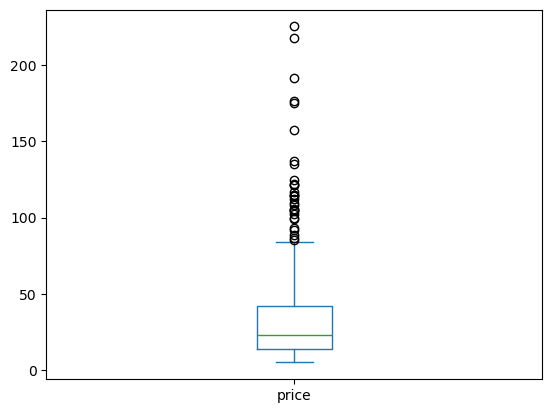

In [133]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
erp_nettoye_web_nettoye_liaison['price'].plot.box()

In [134]:
import plotly.express as px

#Autre méthode avec plotly express
fig = px.box(erp_nettoye, y="price")
fig.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [137]:
#Calculer la moyenne du prix
moyenne_prix = erp_nettoye_web_nettoye_liaison['price'].mean()
print(moyenne_prix)

32.33368347338936


In [138]:
#Calculer l'écart-type du prix
ecart_type_prix = erp_nettoye_web_nettoye_liaison['price'].std()
print(ecart_type_prix)

27.5963324191972


In [139]:
#Calculer le Z-score
erp_nettoye_web_nettoye_liaison['z_price'] = (
    (erp_nettoye_web_nettoye_liaison['price'] - moyenne_prix) / ecart_type_prix
)

<Axes: xlabel='price', ylabel='z_price'>

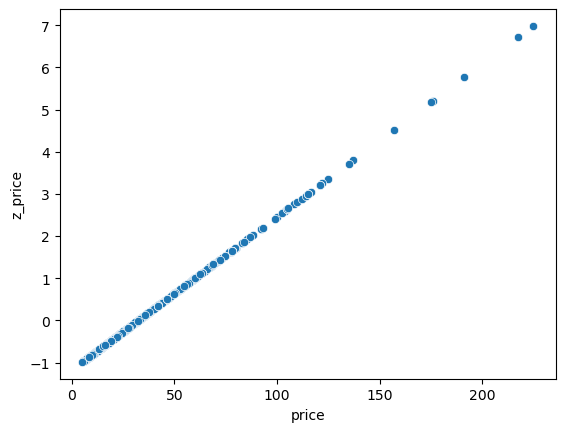

In [140]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
sns.scatterplot(erp_nettoye_web_nettoye_liaison, x = 'price', y='z_price')

Environ 110

Pour être plus précis : 

In [143]:
erp_nettoye_web_nettoye_liaison_inf_trois = erp_nettoye_web_nettoye_liaison[erp_nettoye_web_nettoye_liaison['z_price'] > 3]

In [144]:
erp_nettoye_web_nettoye_liaison_inf_trois['price'].min()

116.4

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [146]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
erp_nettoye_web_nettoye_liaison.describe()

,product_id,price,stock_quantity,purchase_price,average_rating,total_sales,post_author,post_parent,menu_order,comment_count,z_price
count,714.00,714.00,714.00,714.00,714.00,714.00,714.00,714.00,714.00,714.00,714.00
mean,5032.56,32.33,23.45,16.90,0.00,8.52,2.00,0.00,0.00,0.00,-0.00
std,790.51,27.60,22.22,14.83,0.00,8.15,0.04,0.00,0.00,0.00,1.00
min,3847.00,5.20,0.00,2.74,0.00,0.00,1.00,0.00,0.00,0.00,-0.98
25%,4280.25,14.06,9.00,7.24,0.00,5.00,2.00,0.00,0.00,0.00,-0.66
50%,4796.00,23.45,20.00,12.30,0.00,8.00,2.00,0.00,0.00,0.00,-0.32
75%,5710.50,42.08,30.00,22.03,0.00,11.00,2.00,0.00,0.00,0.00,0.35
max,7338.00,225.00,145.00,137.81,0.00,122.00,2.00,0.00,0.00,0.00,6.98


In [147]:
# Outliers

On choisira simplement la méthode de la boite à moustache où la limite supérieure = Q3 + 1,5 * (Q3 -Q2).

In [149]:
fig = px.box(erp_nettoye_web_nettoye_liaison, y="price")
fig.show()

Selon cette définition, les valeurs aberrantes commencent au-delà de 83 euros. Ce qui semble relativement cohérent.

In [151]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
erp_nettoye_web_nettoye_liaison_outliers = erp_nettoye_web_nettoye_liaison[erp_nettoye_web_nettoye_liaison['price'] > 83]

In [152]:
Nb_outliers = len(erp_nettoye_web_nettoye_liaison_outliers)
Total_produit = len(erp_nettoye_web_nettoye_liaison)

Proportion_outlier = Nb_outliers / Total_produit * 100
print(Proportion_outlier)

4.481792717086835


In [153]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?

La définition d'un outlier ou valeur aberrante dépend du contexte, pas seulement d'un calcul.

Pour valider le caractère aberrant des prix de certaines bouteilles, il serait pertinent de comparer ces valeurs à des sources externes pour voir si de tels prix existent. Je pense que oui.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.3 - Identification par le MAD</h3>
</div>

<div style="background-color:RGB(46,125,50); border-radius:8px; padding:18px; margin-top:15px; color:white;"> <h3 style="margin-top:0;">Intérêt de la méthode MAD pour l'identification des valeurs atypiques</h3>

La méthode <b>MAD (Median Absolute Deviation)</b> permet d'identifier les valeurs atypiques en s'appuyant sur la <b>médiane</b> et sur la dispersion des données autour de celle-ci. Contrairement à la moyenne et à l'écart-type, la MAD est une mesure de dispersion <b>robuste aux valeurs extrêmes</b> : quelques chiffres d'affaires exceptionnellement élevés ne viennent donc pas fortement modifier le seuil de détection.

Cette caractéristique est particulièrement intéressante pour l'analyse du <b>chiffre d'affaires</b>, car la distribution des CA peut être fortement déséquilibrée. Quelques produits peuvent en effet générer un chiffre d'affaires beaucoup plus important que la majorité du catalogue. La MAD permet ainsi de repérer ces produits atypiques sans que leur propre valeur ne fausse excessivement la mesure de dispersion utilisée pour les identifier.

Dans cette analyse, le seuil est défini à partir de la <b>médiane du CA + 3 fois la MAD</b>. Les produits dépassant ce seuil sont considérés comme présentant un chiffre d'affaires exceptionnellement élevé par rapport au comportement habituel du catalogue.

La méthode MAD constitue donc un <b>complément à l'approche par intervalle interquartile</b> : elle permet de vérifier si les produits identifiés comme atypiques le sont également avec une méthode statistique différente, tout en étant particulièrement adaptée aux distributions asymétriques et susceptibles de contenir des valeurs extrêmes.

</div>

In [157]:
# Calcul de la médiane du CA
mediane_price = erp_nettoye_web_nettoye_liaison['price'].median()

# Calcul de la Median Absolute Deviation (MAD)
MAD_price = (
    erp_nettoye_web_nettoye_liaison['price'] - mediane_price
).abs().median()

print("Médiane du price :", mediane_price)
print("MAD du price :", MAD_price)

Médiane du price : 23.45
MAD du price : 11.149999999999999


In [158]:
# Calcul du score MAD pour chaque article
erp_nettoye_web_nettoye_liaison['score_MAD_price'] = (
    (erp_nettoye_web_nettoye_liaison['price'] - mediane_price).abs() / MAD_price
)

# Identification des outliers
erp_nettoye_web_nettoye_liaison_outliers = (
    erp_nettoye_web_nettoye_liaison[
        erp_nettoye_web_nettoye_liaison['score_MAD_price'] > 3
    ]
)

erp_nettoye_web_nettoye_liaison_outliers.head()

,product_id,onsale_web,price,stock_quantity,in_stock,purchase_price,id_web,average_rating,total_sales,tax_status,...,ping_status,post_name,post_modified,post_modified_gmt,post_parent,menu_order,post_mime_type,comment_count,z_price,score_MAD_price
8,4043,True,60.00,0,False,29.45,14980,0.00,0.00,taxable,...,closed,pierre-gaillard-cote-rotie-esprit-blond-2017,2020-08-24 14:00:03,2020-08-24 12:00:03,0.00,0.00,NaN,0.00,1.00,3.28
10,4046,True,80.00,2,True,40.92,15269,0.00,2.00,NaN,...,closed,pierre-gaillard-cote-rotie-rose-pourpre-2017,2020-08-24 14:00:03,2020-08-24 12:00:03,0.00,0.00,image/jpeg,0.00,1.73,5.07
18,4054,True,71.60,6,True,38.47,19816,0.00,3.00,NaN,...,closed,clos-du-mont-olivet-chateauneuf-du-pape-papet-...,2020-06-09 15:41:44,2020-06-09 13:41:44,0.00,0.00,image/jpeg,0.00,1.42,4.32
31,4069,True,60.00,4,True,30.07,11862,0.00,3.00,NaN,...,closed,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,0.00,0.00,image/jpeg,0.00,1.00,3.28
35,4073,True,77.80,8,True,40.60,13074,0.00,4.00,NaN,...,closed,chateau-de-vaudieu-chateauneuf-du-pape-lavenue...,2019-12-09 10:40:03,2019-12-09 09:40:03,0.00,0.00,image/jpeg,0.00,1.65,4.87


In [159]:
fig = px.histogram(
    erp_nettoye_web_nettoye_liaison,
    x="score_MAD_price",
    nbins=50,
    title="Distribution du score MAD du price"
)

fig.add_vline(
    x=3,
    line_dash="dash",
    annotation_text="Seuil MAD = 3"
)

fig.show()

In [160]:
# Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"

Nb_outliers = len(erp_nettoye_web_nettoye_liaison_outliers)
Total_produit = len(erp_nettoye_web_nettoye_liaison)

Proportion_outlier = Nb_outliers / Total_produit * 100

# Calcul du seuil correspondant à MAD = 3
Seuil_MAD_3 = mediane_price + (3 * MAD_price)

print("Nombre d'outliers :", Nb_outliers)
print("Nombre total de produits :", Total_produit)
print("Proportion d'outliers :", Proportion_outlier, "%")
print("Seuil correspondant à MAD = 3 :", Seuil_MAD_3)

Nombre d'outliers : 106
Nombre total de produits : 714
Proportion d'outliers : 14.84593837535014 %
Seuil correspondant à MAD = 3 : 56.89999999999999


<div style="background-color:RGB(46,125,50); border-radius:8px; padding:18px; margin-top:15px; color:white;"> <h3 style="margin-top:0;">Comparaison des seuils d'identification des valeurs atypiques</h3>

L'application de la méthode <b>MAD</b> conduit à un seuil de <b>56</b>, contre <b>83</b> avec la méthode de l'<b>intervalle interquartile (IQR)</b>. Cette différence est importante car elle modifie sensiblement le nombre de produits considérés comme atypiques. En effet, un seuil de 56 permet d'identifier des produits dont le chiffre d'affaires est déjà relativement élevé par rapport à la distribution générale, alors que le seuil de 83 ne retient que les valeurs les plus extrêmes.

Cette différence s'explique par le fait que les deux méthodes n'évaluent pas la dispersion des données de la même manière. La méthode IQR s'appuie sur les premier et troisième quartiles, tandis que la MAD repose sur la <b>médiane</b> et sur l'écart absolu médian à celle-ci. La MAD étant particulièrement robuste aux valeurs extrêmes, elle peut ici conduire à un seuil plus faible et donc à une <b>détection plus large des produits atypiques</b>.

Il est donc important de ne pas considérer l'un des deux seuils comme « meilleur » de manière automatique : ils répondent à des approches statistiques différentes. La comparaison des résultats permet plutôt de montrer que le <b>choix de la méthode de détection influence directement l'identification des produits à fort chiffre d'affaires</b>. Dans le cadre de cette analyse, le passage de 83 à 56 élargit ainsi nettement le périmètre des produits considérés comme atypiques selon la méthode MAD.

</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.4 - Identification par Isolation Forest</h3>
</div>

In [163]:
from sklearn.ensemble import IsolationForest

# Création du modèle Isolation Forest
modele_IF = IsolationForest(
    contamination='auto',
    random_state=42
)

# Entraînement du modèle sur le CA
modele_IF.fit(
    erp_nettoye_web_nettoye_liaison[['price']]
)

# Identification des observations
erp_nettoye_web_nettoye_liaison['outlier_IF'] = modele_IF.predict(
    erp_nettoye_web_nettoye_liaison[['price']]
)

In [164]:
# Sélection des produits identifiés comme atypiques
erp_nettoye_web_nettoye_liaison_outliers_IF = (
    erp_nettoye_web_nettoye_liaison[
        erp_nettoye_web_nettoye_liaison['outlier_IF'] == -1
    ]
)

erp_nettoye_web_nettoye_liaison_outliers_IF.head(20)

,product_id,onsale_web,price,stock_quantity,in_stock,purchase_price,id_web,average_rating,total_sales,tax_status,...,post_name,post_modified,post_modified_gmt,post_parent,menu_order,post_mime_type,comment_count,z_price,score_MAD_price,outlier_IF
10,4046,True,80.00,2,True,40.92,15269,0.00,2.00,NaN,...,pierre-gaillard-cote-rotie-rose-pourpre-2017,2020-08-24 14:00:03,2020-08-24 12:00:03,0.00,0.00,image/jpeg,0.00,1.73,5.07,-1
15,4051,True,7.70,0,False,4.14,16045,0.00,0.00,NaN,...,pierre-gaillard-syrah-terre-mandrin-2018,2020-08-27 17:15:02,2020-08-27 15:15:02,0.00,0.00,image/jpeg,0.00,-0.89,1.41,-1
18,4054,True,71.60,6,True,38.47,19816,0.00,3.00,NaN,...,clos-du-mont-olivet-chateauneuf-du-pape-papet-...,2020-06-09 15:41:44,2020-06-09 13:41:44,0.00,0.00,image/jpeg,0.00,1.42,4.32,-1
35,4073,True,77.80,8,True,40.60,13074,0.00,4.00,NaN,...,chateau-de-vaudieu-chateauneuf-du-pape-lavenue...,2019-12-09 10:40:03,2019-12-09 09:40:03,0.00,0.00,image/jpeg,0.00,1.65,4.87,-1
59,4105,True,6.80,45,True,3.51,16504,0.00,16.00,taxable,...,emile-boeckel-sylvaner-vieilles-vignes-2019,2020-08-27 09:28:39,2020-08-27 07:28:39,0.00,0.00,NaN,0.00,-0.93,1.49,-1
63,4115,True,100.00,12,True,52.70,15382,0.00,1.00,NaN,...,zind-humbrecht-riesling-gc-rangen-thann-clos-s...,2020-02-08 11:45:02,2020-02-08 10:45:02,0.00,0.00,image/jpeg,0.00,2.45,6.87,-1
65,4132,True,88.40,7,True,44.30,11668,0.00,5.00,taxable,...,zind-humbrecht-pinot-gris-grand-cru-rangen-de-...,2020-02-20 09:55:02,2020-02-20 08:55:02,0.00,0.00,NaN,0.00,2.03,5.83,-1
68,4139,True,77.40,1,True,39.59,13217,0.00,1.00,NaN,...,zind-humbrecht-gewurzt-grand-cru-rangen-de-tha...,2019-07-08 09:30:39,2019-07-08 07:30:39,0.00,0.00,image/jpeg,0.00,1.63,4.84,-1
70,4142,True,53.00,125,True,32.15,11641,0.00,4.00,NaN,...,champagne-gosset-grand-millesime-2006,2020-08-20 09:30:03,2020-08-20 07:30:03,0.00,0.00,image/jpeg,0.00,0.75,2.65,-1
75,4149,True,69.00,101,True,40.25,7086,0.00,5.00,taxable,...,champagne-mailly-grand-cru-intemporelle-rose-2009,2020-08-20 09:30:19,2020-08-20 07:30:19,0.00,0.00,NaN,0.00,1.33,4.09,-1


In [165]:
# Définir le nombre d'articles et la proportion du catalogue "outliers"

Nb_outliers_IF = len(erp_nettoye_web_nettoye_liaison_outliers_IF)
Total_produit = len(erp_nettoye_web_nettoye_liaison)

Proportion_outlier_IF = Nb_outliers_IF / Total_produit * 100

print("Nombre d'outliers :", Nb_outliers_IF)
print("Nombre total de produits :", Total_produit)
print("Proportion d'outliers :", Proportion_outlier_IF, "%")

Nombre d'outliers : 121
Nombre total de produits : 714
Proportion d'outliers : 16.946778711484594 %


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [168]:
erp_nettoye_web_nettoye_liaison.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'in_stock',
       'purchase_price', 'id_web', 'average_rating', 'total_sales',
       'tax_status', 'post_author', 'post_date', 'post_date_gmt',
       'product_type', 'post_title', 'post_excerpt', 'post_status',
       'comment_status', 'ping_status', 'post_name', 'post_modified',
       'post_modified_gmt', 'post_parent', 'menu_order', 'post_mime_type',
       'comment_count', 'z_price', 'score_MAD_price', 'outlier_IF'],
      dtype='object')

In [169]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
erp_nettoye_web_nettoye_liaison['CA'] = erp_nettoye_web_nettoye_liaison['price'] * erp_nettoye_web_nettoye_liaison['total_sales']



In [170]:
#Calculer la somme de la colonne "ca_par_article"

#Ce résultat correspond au chiffre d'affaire du site web

erp_nettoye_web_nettoye_liaison['CA'].sum()

153748.1

In [171]:
###############################
# Palmarès des articles en CA #
###############################

# Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
erp_nettoye_web_nettoye_liaison = erp_nettoye_web_nettoye_liaison.sort_values(
    by='CA',
    ascending=False
)

# Réinitialiser l'index du dataset
erp_nettoye_web_nettoye_liaison = erp_nettoye_web_nettoye_liaison.reset_index(drop=True)

# Afficher les 20 premiers articles en CA
erp_nettoye_web_nettoye_liaison.head(20)



,product_id,onsale_web,price,stock_quantity,in_stock,purchase_price,id_web,average_rating,total_sales,tax_status,...,post_modified,post_modified_gmt,post_parent,menu_order,post_mime_type,comment_count,z_price,score_MAD_price,outlier_IF,CA
0,4150,True,59.00,123,True,35.45,1366,0.00,116.00,NaN,...,2020-08-26 18:05:02,2020-08-26 16:05:02,0.00,0.00,image/jpeg,0.00,0.97,3.19,1,6844.00
1,4352,True,225.00,0,False,137.81,15940,0.00,11.00,NaN,...,2020-03-07 11:18:45,2020-03-07 10:18:45,0.00,0.00,image/jpeg,0.00,6.98,18.08,-1,2475.00
2,4726,True,12.70,0,False,6.82,14950,0.00,122.00,NaN,...,2020-05-06 11:35:01,2020-05-06 09:35:01,0.00,0.00,image/jpeg,0.00,-0.71,0.96,1,1549.40
3,5067,True,59.90,3,True,30.95,15346,0.00,22.00,NaN,...,2020-02-13 17:00:01,2020-02-13 16:00:01,0.00,0.00,image/jpeg,0.00,1.00,3.27,1,1317.80
4,5379,True,11.10,33,True,5.68,14561,0.00,111.00,NaN,...,2020-07-11 14:00:03,2020-07-11 12:00:03,0.00,0.00,image/jpeg,0.00,-0.77,1.11,1,1232.10
5,5892,True,191.30,98,True,116.06,14983,0.00,6.00,NaN,...,2020-04-01 09:30:09,2020-04-01 07:30:09,0.00,0.00,image/jpeg,0.00,5.76,15.05,-1,1147.80
6,4353,True,79.50,127,True,45.91,12587,0.00,14.00,taxable,...,2020-08-22 11:45:02,2020-08-22 09:45:02,0.00,0.00,NaN,0.00,1.71,5.03,-1,1113.00
7,5826,True,41.20,34,True,21.71,15325,0.00,20.00,NaN,...,2020-05-21 14:00:02,2020-05-21 12:00:02,0.00,0.00,image/jpeg,0.00,0.32,1.59,1,824.00
8,6212,True,115.00,16,True,59.42,13996,0.00,7.00,NaN,...,2020-06-16 09:30:16,2020-06-16 07:30:16,0.00,0.00,image/jpeg,0.00,3.00,8.21,-1,805.00
9,5026,True,86.80,101,True,50.13,13913,0.00,9.00,NaN,...,2020-05-11 14:35:02,2020-05-11 12:35:02,0.00,0.00,image/jpeg,0.00,1.97,5.68,-1,781.20


In [172]:
# Graphique en barres des 20 premiers articles avec Plotly Express

# Trier le DataFrame par CA décroissant et prendre les 20 premiers
top20 = (
    erp_nettoye_web_nettoye_liaison
    .sort_values(by='CA', ascending=False)
    .head(20)
)

# Créer le graphique en barres
fig = px.bar(
    top20,
    x='post_title',
    y='CA',
    text='CA',
    labels={
        'post_title': 'Produit',
        'CA': 'Chiffre d\'affaires'
    },
    title='Top 20 des articles par CA'
)

# Adapter la mise en page pour l'export
fig.update_layout(
    width=1000,
    height=600,
    xaxis_tickangle=-45,
    xaxis_title='Produit',
    yaxis_title='Chiffre d\'affaires',
    margin=dict(l=60, r=40, t=80, b=180)
)

# Affichage interactif dans le notebook
fig.show()

Pour la présentation on va le refaire en enlevant les légendes de colonnes :

In [174]:
# Graphique en barres des 20 premiers articles avec Plotly Express

# Trier le DataFrame par CA décroissant et prendre les 20 premiers
top20 = (
    erp_nettoye_web_nettoye_liaison
    .sort_values(by='CA', ascending=False)
    .head(20)
)

# Créer le graphique en barres
fig = px.bar(
    top20,
    x='post_title',
    y='CA',
    labels={
        'post_title': 'Produit',
        'CA': 'Chiffre d\'affaires'
    },
    title='Top 20 des articles par CA'
)

# Adapter la mise en page
fig.update_layout(
    width=1000,
    height=600,
    xaxis_title='Produit',
    yaxis_title='Chiffre d\'affaires',
    xaxis_showticklabels=False,
    margin=dict(l=60, r=40, t=80, b=60)
)

# Aucun texte sur les barres
fig.update_traces(text=None)

# Affichage interactif
fig.show()

In [175]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
erp_nettoye_web_nettoye_liaison['%CA'] = (erp_nettoye_web_nettoye_liaison['CA'] / erp_nettoye_web_nettoye_liaison['CA'].sum()) * 100


In [176]:
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée

erp_nettoye_web_nettoye_liaison_filtre = erp_nettoye_web_nettoye_liaison.sort_values(by = '%CA', ascending = True)

# Créer la colonne de pourcentage cumulé
erp_nettoye_web_nettoye_liaison_filtre['%CA_cumul'] = erp_nettoye_web_nettoye_liaison_filtre['%CA'].cumsum()


In [177]:
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA

erp_nettoye_web_nettoye_liaison_80 = erp_nettoye_web_nettoye_liaison_filtre[erp_nettoye_web_nettoye_liaison_filtre['%CA_cumul'] > 80]

#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web

Proportion_art_80_CA = len(erp_nettoye_web_nettoye_liaison_80)/ len(erp_nettoye_web_nettoye_liaison) * 100

In [178]:
print(Proportion_art_80_CA)

4.621848739495799


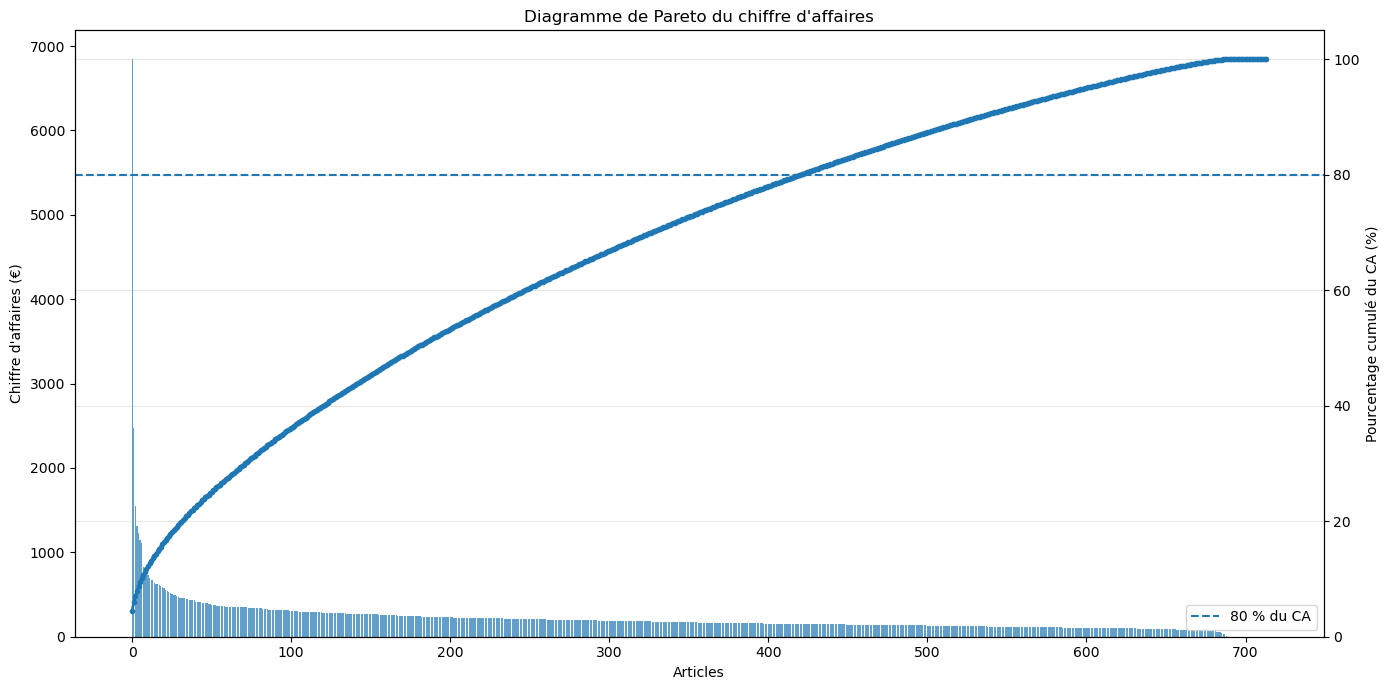

In [179]:
import matplotlib.pyplot as plt

#############################
# Graphique de Pareto - CA  #
#############################

# Trier les articles par CA décroissant
erp_pareto = erp_nettoye_web_nettoye_liaison.sort_values(
    by='CA',
    ascending=False
).copy()

# Calculer la part du CA de chaque article
erp_pareto['%CA'] = (
    erp_pareto['CA'] / erp_pareto['CA'].sum()
) * 100

# Calculer le pourcentage cumulé
erp_pareto['%CA_cumul'] = erp_pareto['%CA'].cumsum()

# Créer le graphique
fig, ax1 = plt.subplots(figsize=(14, 7))

# Barres = CA de chaque article
ax1.bar(
    range(len(erp_pareto)),
    erp_pareto['CA'],
    alpha=0.7
)

ax1.set_xlabel("Articles")
ax1.set_ylabel("Chiffre d'affaires (€)")
ax1.set_title("Diagramme de Pareto du chiffre d'affaires")

# Deuxième axe pour le CA cumulé
ax2 = ax1.twinx()

ax2.plot(
    range(len(erp_pareto)),
    erp_pareto['%CA_cumul'],
    marker='.',
    linewidth=2
)

# Ligne des 80 %
ax2.axhline(
    y=80,
    linestyle='--',
    linewidth=1.5,
    label='80 % du CA'
)

# Limites de l'axe Y
ax2.set_ylim(0, 105)
ax2.set_ylabel("Pourcentage cumulé du CA (%)")

# Ajouter une grille
ax2.grid(axis='y', alpha=0.3)

# Légende
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [181]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
erp_nettoye_web_nettoye_liaison_tri_quant = erp_nettoye_web_nettoye_liaison.sort_values(by = 'total_sales', ascending= False)
#Réinitialiser l'index du dataset par un reset_index
erp_nettoye_web_nettoye_liaison_tri_quant.reset_index()
#Afficher les 20 premiers articles en quantité
erp_nettoye_web_nettoye_liaison_tri_quant.head(20)



,product_id,onsale_web,price,stock_quantity,in_stock,purchase_price,id_web,average_rating,total_sales,tax_status,...,post_modified_gmt,post_parent,menu_order,post_mime_type,comment_count,z_price,score_MAD_price,outlier_IF,CA,%CA
2,4726,True,12.70,0,False,6.82,14950,0.00,122.00,NaN,...,2020-05-06 09:35:01,0.00,0.00,image/jpeg,0.00,-0.71,0.96,1,1549.40,1.01
0,4150,True,59.00,123,True,35.45,1366,0.00,116.00,NaN,...,2020-08-26 16:05:02,0.00,0.00,image/jpeg,0.00,0.97,3.19,1,6844.00,4.45
4,5379,True,11.10,33,True,5.68,14561,0.00,111.00,NaN,...,2020-07-11 12:00:03,0.00,0.00,image/jpeg,0.00,-0.77,1.11,1,1232.10,0.80
64,4867,True,9.90,121,True,4.86,16148,0.00,36.00,taxable,...,2020-08-27 07:30:15,0.00,0.00,NaN,0.00,-0.81,1.22,1,356.40,0.23
144,4203,True,9.90,74,True,5.01,15415,0.00,27.00,taxable,...,2020-07-11 14:45:03,0.00,0.00,NaN,0.00,-0.81,1.22,1,267.30,0.17
59,4275,True,14.90,62,True,7.78,14864,0.00,24.00,taxable,...,2020-08-22 12:35:02,0.00,0.00,NaN,0.00,-0.63,0.77,1,357.60,0.23
3,5067,True,59.90,3,True,30.95,15346,0.00,22.00,NaN,...,2020-02-13 16:00:01,0.00,0.00,image/jpeg,0.00,1.00,3.27,1,1317.80,0.86
16,4647,True,28.50,45,True,14.14,16525,0.00,22.00,taxable,...,2020-07-31 07:31:39,0.00,0.00,NaN,0.00,-0.14,0.45,1,627.00,0.41
7,5826,True,41.20,34,True,21.71,15325,0.00,20.00,NaN,...,2020-05-21 12:00:02,0.00,0.00,image/jpeg,0.00,0.32,1.59,1,824.00,0.54
607,6129,True,5.20,68,True,2.74,14570,0.00,20.00,taxable,...,2020-08-26 13:55:02,0.00,0.00,NaN,0.00,-0.98,1.64,-1,104.00,0.07


In [182]:
# Graphique en barres des 20 premiers articles par nombre de ventes

# Trier le DataFrame par total_sales décroissant et prendre les 20 premiers
top20_quant = (
    erp_nettoye_web_nettoye_liaison
    .sort_values(by='total_sales', ascending=False)
    .head(20)
)

# Créer le graphique en barres
fig = px.bar(
    top20_quant,
    x='post_title',
    y='total_sales',
    text='total_sales',
    labels={
        'post_title': 'Produit',
        'total_sales': 'Total des ventes'
    },
    title='Top 20 des articles par total_sales'
)

# Adapter la mise en page
fig.update_layout(
    width=1000,
    height=600,
    xaxis_tickangle=-45,
    xaxis_title='Produit',
    yaxis_title='Total des ventes',
    margin=dict(l=60, r=40, t=80, b=180)
)

# Affichage interactif dans le notebook
fig.show()

Pour la présentation, on va le refaire en enlevant les légendes de colonnes :

In [184]:
# Graphique en barres des 20 premiers articles par total_sales

top20_quant = (
    erp_nettoye_web_nettoye_liaison
    .sort_values(by='total_sales', ascending=False)
    .head(20)
)

fig = px.bar(
    top20_quant,
    x='post_title',
    y='total_sales',
    labels={
        'post_title': 'Produit',
        'total_sales': 'Total des ventes'
    },
    title='Top 20 des articles par total_sales'
)

# Mise en forme pour éviter le tronquage lors de l'export
fig.update_layout(
    width=1000,
    height=600,
    xaxis_title='Produit',
    yaxis_title='Total des ventes',
    xaxis_showticklabels=False,
    margin=dict(l=60, r=40, t=80, b=60)
)

# Aucun texte sur les barres
fig.update_traces(text=None)


# Export en image statique pour le PDF
fig.show()


In [185]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset
erp_nettoye_web_nettoye_liaison['%total_sales'] = (erp_nettoye_web_nettoye_liaison['total_sales'] / erp_nettoye_web_nettoye_liaison['total_sales'].sum()) * 100
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
erp_nettoye_web_nettoye_liaison_filtre_sales = erp_nettoye_web_nettoye_liaison.sort_values(by = '%total_sales', ascending = True)
erp_nettoye_web_nettoye_liaison_filtre_sales['%total_sales_cumul'] = erp_nettoye_web_nettoye_liaison_filtre_sales['%total_sales'].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
erp_nettoye_web_nettoye_liaison_filtre_sales_80 = erp_nettoye_web_nettoye_liaison_filtre_sales[erp_nettoye_web_nettoye_liaison_filtre_sales['%total_sales_cumul'] > 80]
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
Proportion_art_80_sales = len(erp_nettoye_web_nettoye_liaison_filtre_sales_80)/ len(erp_nettoye_web_nettoye_liaison) * 100
print(Proportion_art_80_sales)

7.9831932773109235


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [187]:
######################################
# Calculer le nombre de mois de stock #
######################################

import numpy as np

# Création de la colonne Mois_stock
erp_nettoye_web_nettoye_liaison['Mois_stock'] = (
    erp_nettoye_web_nettoye_liaison['stock_quantity']
    / erp_nettoye_web_nettoye_liaison['total_sales']
).round(1)

# Remplacement des valeurs infinies par 0
erp_nettoye_web_nettoye_liaison['Mois_stock'] = (
    erp_nettoye_web_nettoye_liaison['Mois_stock']
    .replace([np.inf, -np.inf], 0)
    .clip(lower=0)
)

# Tri décroissant du nombre de mois de stock
erp_nettoye_web_nettoye_liaison = (
    erp_nettoye_web_nettoye_liaison
    .sort_values(by='Mois_stock', ascending=False)
    .reset_index(drop=True)
)

# Sélection des 20 produits ayant le plus de mois de stock
top20_mois_stock = erp_nettoye_web_nettoye_liaison.head(20)

# Création du graphique en barres
fig = px.bar(
    top20_mois_stock,
    x='post_title',
    y='Mois_stock',
    labels={
        'post_title': 'Produit',
        'Mois_stock': 'Mois de stock'
    },
    title='Top 20 des articles par mois de stock'
)

# Mise en forme
fig.update_layout(
    width=1000,
    height=600,
    xaxis_title='Produit',
    yaxis_title='Mois de stock',
    xaxis_showticklabels=False,
    margin=dict(l=60, r=40, t=80, b=60)
)

# Aucun texte sur les barres
fig.update_traces(text=None)

# Affichage interactif dans le notebook
fig.show()



Pour la présentation, on va inverser les axes et enlever les légendes qui gênent la lecture : 

In [189]:
# Graphique en barres horizontales du Top 20 des produits
# avec le plus de mois de stock

top20_mois_stock = (
    erp_nettoye_web_nettoye_liaison
    .head(20)
)

# Création du graphique en barres horizontales
fig = px.bar(
    top20_mois_stock,
    x='Mois_stock',
    y='post_title',
    labels={
        'post_title': 'Produit',
        'Mois_stock': 'Mois de stock'
    },
    title='Top 20 des articles par mois de stock'
)

# Mise en forme
fig.update_layout(
    width=800,
    height=900,
    xaxis_title='Mois de stock',
    yaxis_title='Produit',
    yaxis_showticklabels=False,
    margin=dict(l=60, r=40, t=80, b=60)
)

# Aucun texte sur les barres
fig.update_traces(text=None)

# Affichage interactif dans le notebook
fig.show()


In [190]:
top20_mois_stock[['post_title', 'Mois_stock']].head(5)

,post_title,Mois_stock
0,Champagne Gosset Grand Millésime 2006,31.20
1,Champagne Gosset Célébris Vintage 2007,27.60
2,Champagne Egly-Ouriet Premier Cru Les Vignes d...,27.00
3,Champagne Egly-Ouriet Grand Cru Brut Tradition,25.00
4,Champagne Mailly Grand Cru Brut Rosé,23.70


In [191]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
erp_nettoye_web_nettoye_liaison['valorisation'] = erp_nettoye_web_nettoye_liaison['price'] * erp_nettoye_web_nettoye_liaison['stock_quantity']
#Calculer la somme de la colonne "Valorisation_stock_euros"
somme_valorisation = erp_nettoye_web_nettoye_liaison['valorisation'].sum()
print(somme_valorisation)

494637.9


In [192]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
valorisation_stock = erp_nettoye_web_nettoye_liaison['stock_quantity'].sum()
print(valorisation_stock)

16740


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [194]:
erp_nettoye_web_nettoye_liaison.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'in_stock',
       'purchase_price', 'id_web', 'average_rating', 'total_sales',
       'tax_status', 'post_author', 'post_date', 'post_date_gmt',
       'product_type', 'post_title', 'post_excerpt', 'post_status',
       'comment_status', 'ping_status', 'post_name', 'post_modified',
       'post_modified_gmt', 'post_parent', 'menu_order', 'post_mime_type',
       'comment_count', 'z_price', 'score_MAD_price', 'outlier_IF', 'CA',
       '%CA', '%total_sales', 'Mois_stock', 'valorisation'],
      dtype='object')

In [195]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
erp_nettoye_web_nettoye_liaison['Prix_HT'] = erp_nettoye_web_nettoye_liaison['price'] * 0.8
#Création de la colonne Taux de marge
erp_nettoye_web_nettoye_liaison['Taux_marge'] = ((erp_nettoye_web_nettoye_liaison['Prix_HT'] - erp_nettoye_web_nettoye_liaison['purchase_price']) / erp_nettoye_web_nettoye_liaison['Prix_HT']) * 100
#Afficher le prix minimum de la colonne "taux_marge"
print(erp_nettoye_web_nettoye_liaison['Taux_marge'].min())
#Afficher le prix maximum de la colonne "taux_marge"
print(erp_nettoye_web_nettoye_liaison['Taux_marge'].max())

-665.6126482213438
45.58


In [196]:
#Affichage de la ligne avec un taux de marge inférieur à 0
neg_marge = erp_nettoye_web_nettoye_liaison.loc[
    erp_nettoye_web_nettoye_liaison['Taux_marge'] < 0
]

print(neg_marge)

     product_id  onsale_web  price  stock_quantity  in_stock  purchase_price  \
691        4355        True  12.65              97      True           77.48   

    id_web  average_rating  total_sales tax_status  ...  z_price  \
691  12589            0.00         0.00    taxable  ...    -0.71   

    score_MAD_price outlier_IF   CA  %CA %total_sales Mois_stock valorisation  \
691            0.97          1 0.00 0.00         0.00       0.00      1227.05   

    Prix_HT Taux_marge  
691   10.12    -665.61  

[1 rows x 36 columns]


<div style="background-color:RGB(46,125,50);
            border-radius:8px;
            padding:18px;
            margin-top:15px;
            color:white;">

<h3 style="margin-top:0;">Traitement d'une valeur de marge atypique</h3>

Lors de l'analyse des taux de marge, une valeur particulièrement atypique a été identifiée pour le <b>produit 4355</b>, avec un taux de marge de <b>-665,6 %</b>. Ce résultat s'explique par un prix de vente de <b>12,65 €</b> pour un prix d'achat de <b>77,48 €</b>, ce qui correspond à une vente largement inférieure au coût d'achat.

Cette valeur a été <b>exclue du calcul de la moyenne des taux de marge</b> au moyen d'un filtre conservant uniquement les taux de marge positifs. Ce choix vise à éviter qu'une valeur extrêmement atypique ne déforme l'indicateur moyen utilisé pour caractériser la marge des produits.

Il est toutefois important de distinguer <b>l'exclusion d'une valeur d'un indicateur statistique</b> et la suppression de la donnée elle-même. Le produit 4355 n'est pas supprimé des données sources : son taux de marge négatif constitue une <b>anomalie à investiguer</b>. Il peut correspondre à une erreur de saisie, à une erreur de référencement du prix d'achat ou à une situation commerciale réelle dans laquelle le produit est vendu à perte.

Dans le cadre de l'amélioration du projet, cette valeur est donc désormais <b>identifiée et documentée comme une anomalie</b>, plutôt que d'être simplement écartée sans explication. Une vérification de la cohérence du prix de vente et du prix d'achat serait nécessaire avant toute éventuelle correction de la donnée source.

</div>


In [198]:
#Création d'un dataframe avec les taux positifs
pos_marge = erp_nettoye_web_nettoye_liaison.loc[
    erp_nettoye_web_nettoye_liaison['Taux_marge'] > 0
]
#Afficher le prix minimum de la colonne "taux_marge"
print(pos_marge['Taux_marge'].min())
#Afficher le prix maximum de la colonne "taux_marge"
print(pos_marge['Taux_marge'].max())
#Afficher la moyenne de la colonne "taux_marge"
print(pos_marge['Taux_marge'].mean())

19.561068702290083
45.58
35.231736144419834


In [199]:
#Création d'un dataframe avec le taux de marge moyen par type de produit

taux_moyen_par_produit = pos_marge.groupby('product_type')['Taux_marge'].mean().reset_index()
taux_moyen_par_produit['Taux_marge'] = taux_moyen_par_produit['Taux_marge'].round(1)
print(taux_moyen_par_produit)

#Affichage dans un graphique du taux de marge par type de produit


    product_type  Taux_marge
0          Autre       33.50
1      Champagne       25.50
2         Cognac       42.80
3            Gin       40.40
4  Huile d'olive       21.90
5            Vin       35.40
6         Whisky       42.60


In [200]:
# Affichage du taux de marge moyen par type de produit

import plotly.express as px

fig = px.bar(
    taux_moyen_par_produit,
    x='product_type',
    y='Taux_marge',
    text='Taux_marge',
    labels={
        'product_type': 'Type de produit',
        'Taux_marge': 'Taux de marge (%)'
    },
    title='Taux de marge moyen par type de produit'
)

# Mise en forme
fig.update_layout(
    width=900,
    height=600,
    xaxis_tickangle=-45,
    xaxis_title='Type de produit',
    yaxis_title='Taux de marge (%)',
    margin=dict(l=60, r=40, t=80, b=120),
    uniformtext_minsize=8,
    uniformtext_mode='hide'
)

# Affichage du taux de marge sur les barres
fig.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='outside'
)

# Affichage interactif dans le notebook
fig.show()


In [201]:
from scipy.stats import kruskal

# Sélection des variables nécessaires
df_marge = erp_nettoye_web_nettoye_liaison[
    ['product_type', 'Taux_marge']
].dropna()

# Création des groupes selon le type de produit
groupes_marge = [
    groupe['Taux_marge'].values
    for _, groupe in df_marge.groupby('product_type')
]

In [202]:
# Réalisation du test de Kruskal-Wallis
statistique, p_value = kruskal(*groupes_marge)

print("Statistique de Kruskal-Wallis :", statistique)
print("p-value :", p_value)

Statistique de Kruskal-Wallis : 152.8469151210295
p-value : 1.93420127851133e-30


In [203]:
# Niveau de significativité
alpha = 0.05

if p_value < alpha:
    print("La différence de taux de marge entre les types de produits est statistiquement significative.")
else:
    print("Aucune différence statistiquement significative du taux de marge entre les types de produits n'est mise en évidence.")

La différence de taux de marge entre les types de produits est statistiquement significative.


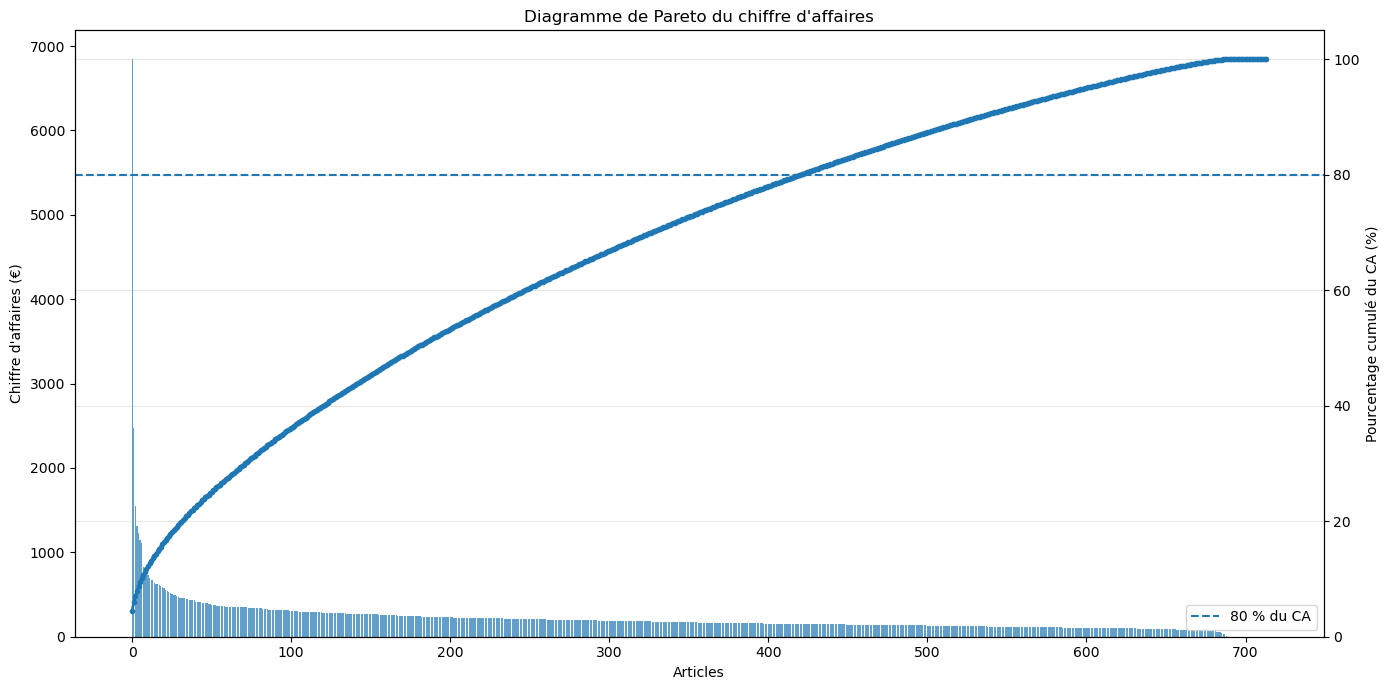

In [204]:
import matplotlib.pyplot as plt

#############################
# Graphique de Pareto - CA  #
#############################

# Trier les articles par CA décroissant
erp_pareto = erp_nettoye_web_nettoye_liaison.sort_values(
    by='CA',
    ascending=False
).copy()

# Calculer la part du CA de chaque article
erp_pareto['%CA'] = (
    erp_pareto['CA'] / erp_pareto['CA'].sum()
) * 100

# Calculer le pourcentage cumulé
erp_pareto['%CA_cumul'] = erp_pareto['%CA'].cumsum()

# Créer le graphique
fig, ax1 = plt.subplots(figsize=(14, 7))

# Barres = CA de chaque article
ax1.bar(
    range(len(erp_pareto)),
    erp_pareto['CA'],
    alpha=0.7
)

ax1.set_xlabel("Articles")
ax1.set_ylabel("Chiffre d'affaires (€)")
ax1.set_title("Diagramme de Pareto du chiffre d'affaires")

# Deuxième axe pour le CA cumulé
ax2 = ax1.twinx()

ax2.plot(
    range(len(erp_pareto)),
    erp_pareto['%CA_cumul'],
    marker='.',
    linewidth=2
)

# Ligne des 80 %
ax2.axhline(
    y=80,
    linestyle='--',
    linewidth=1.5,
    label='80 % du CA'
)

# Limites de l'axe Y
ax2.set_ylim(0, 105)
ax2.set_ylabel("Pourcentage cumulé du CA (%)")

# Ajouter une grille
ax2.grid(axis='y', alpha=0.3)

# Légende
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

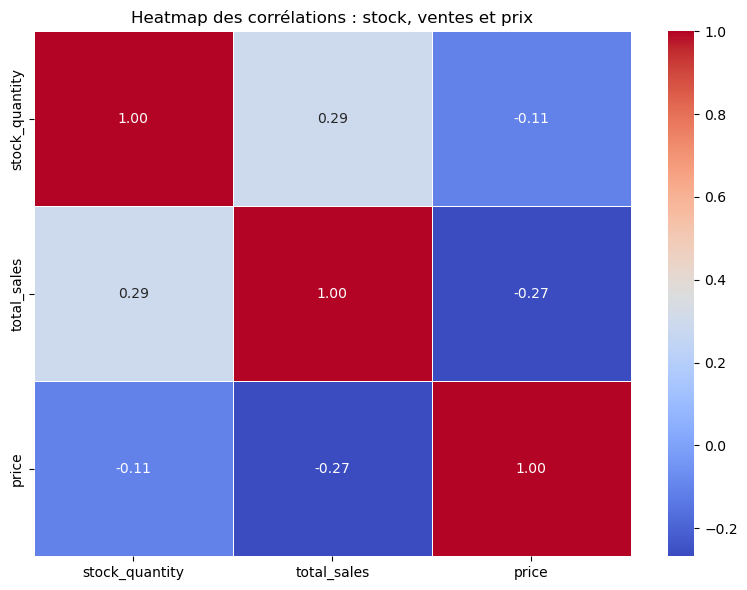

In [206]:
############################
# Analyse des corrélations #
############################

import matplotlib.pyplot as plt
import seaborn as sns

# Sélection des variables quantitatives
df_corr = erp_nettoye_web_nettoye_liaison[
    ['stock_quantity', 'total_sales', 'price']
]

# Calcul de la matrice de corrélation
corr = df_corr.corr()

# Création de la heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    linewidths=.5,
    fmt=".2f"
)

plt.title("Heatmap des corrélations : stock, ventes et prix")
plt.tight_layout()

# Enregistrement en haute résolution pour le PDF
plt.savefig("heatmap_correlations.png", dpi=300, bbox_inches='tight')

plt.show()


In [207]:
#Que peut-on conclure des corrélations ?

Le prix de vente est négativement corrélé au nombre de ventes (déjà vu, voir plus haut), ce qui est normal et cohérent (les articles chers sont peu vendus). 

Par contre, le nombre de ventes est positivement corrélé aux quantités en stock, ce qui est une bonne chose. 

Encore une fois, logiquement les quantités en stock ne sont pas corrélées au prix. 

On va également sortir la demi-heatmap pour la présentation :

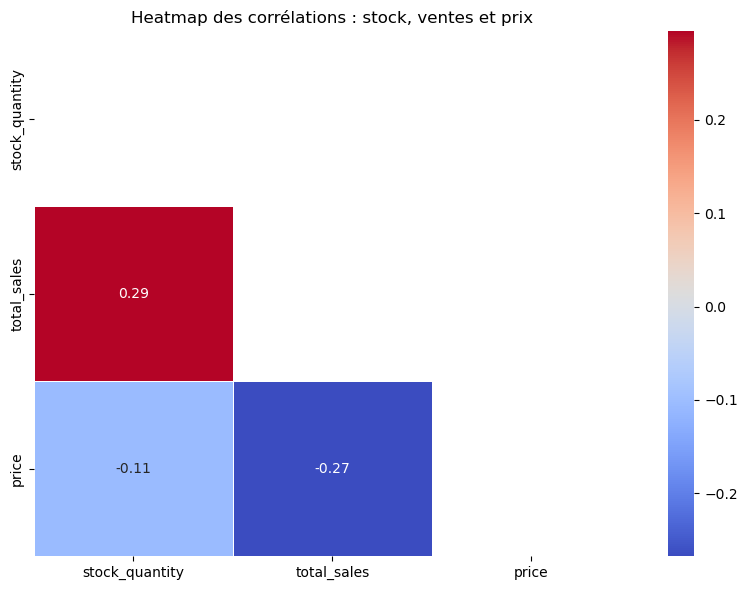

In [210]:
# Sélection des variables
df_corr = erp_nettoye_web_nettoye_liaison[
    ['stock_quantity', 'total_sales', 'price']
]

# Calcul de la matrice de corrélation
corr = df_corr.corr()

# Création du mask : on cache la moitié supérieure de la matrice
mask = np.triu(np.ones_like(corr, dtype=bool))

# Création de la heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    cmap='coolwarm',
    linewidths=.5,
    fmt=".2f"
)

plt.title("Heatmap des corrélations : stock, ventes et prix")
plt.tight_layout()

# Enregistrement en haute résolution pour le PDF
plt.savefig(
    "heatmap_correlations.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


<div style="background-color:RGB(46,125,50); border-radius:8px; padding:18px; margin-top:15px; color:white;"> <h3 style="margin-top:0;">Pourquoi utiliser la corrélation de Spearman ?</h3>

La heatmap initiale repose sur la <b>corrélation de Pearson</b>, qui mesure principalement l'intensité d'une relation <b>linéaire</b> entre deux variables. Or, dans notre analyse, les variables <b>stock_quantity</b>, <b>total_sales</b> et <b>price</b> ne présentent pas nécessairement des relations linéaires et certaines, notamment le prix, ne suivent pas une distribution normale. La corrélation de <b>Spearman</b> apparaît donc plus adaptée : elle repose sur le <b>classement des observations</b> plutôt que sur leurs valeurs brutes et permet d'identifier des relations <b>monotones</b>, y compris lorsqu'elles ne suivent pas une droite. Cette méthode offre ainsi une lecture plus robuste des relations entre les variables étudiées.

In [212]:
# Calcul de la matrice de corrélation de Spearman
corr_spearman = erp_nettoye_web_nettoye_liaison[
    ['stock_quantity', 'total_sales', 'price']
].corr(method='spearman')

# Affichage de la matrice
corr_spearman

,stock_quantity,total_sales,price
stock_quantity,1.00,0.76,-0.57
total_sales,0.76,1.00,-0.69
price,-0.57,-0.69,1.00


In [213]:
import plotly.express as px

fig = px.imshow(
    corr_spearman,
    text_auto=True,
    title="Matrice de corrélation de Spearman"
)

fig.show()

</div> <div style="background-color:RGB(46,125,50); border-radius:8px; padding:18px; margin-top:15px; color:white;"> <h3 style="margin-top:0;">Une relation négative entre le prix et le stock</h3>

L'utilisation de la corrélation de Spearman fait apparaître une différence importante par rapport aux résultats obtenus avec Pearson. Alors que la corrélation de Pearson ne mettait pas en évidence de relation négative suffisamment marquée entre le <b>prix</b> et la <b>quantité en stock</b>, Spearman révèle une <b>corrélation négative inférieure à -0,5</b>. Cela signifie qu'il existe une relation monotone négative relativement marquée entre ces deux variables : dans les données étudiées, les produits ayant tendance à être <b>plus chers sont également associés à des niveaux de stock plus faibles</b>, tandis que les produits moins chers tendent à présenter des stocks plus importants. Cette différence illustre l'intérêt de Spearman dans notre analyse, car une relation peut être suffisamment structurée pour être détectée par les <b>rangs</b>, sans nécessairement présenter une relation linéaire suffisamment forte pour être identifiée par Pearson.

</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

Attention, choisissez bien votre dossier !

In [217]:
# Mettre le dataset df_merge sur un fichier Excel
# Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.

erp_nettoye_web_nettoye_liaison.to_excel(
    r"C:\Users\victo\OneDrive\Dokumente\Projet OC\OCP6\df_merge.xlsx",
    index=False
)

print("Fichier Excel créé avec succès.")

Fichier Excel créé avec succès.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Conclusion partie analytique : </h3>
</div>

L'analyse exploratoire des trois fichiers sources a permis de fiabiliser les variables nécessaires aux indicateurs commerciaux (prix, stock, quantités vendues, prix d'achat) avant même la préparation complète du jeu de données. Plusieurs incohérences ponctuelles ont été corrigées à ce stade : des prix négatifs (erreurs de saisie) ramenés en valeur positive, des quantités en stock négatives ramenées à 0, ainsi que des incohérences entre variables booléennes (in_stock, onsale_web) et la quantité en stock. La relation entre onsale_web et stock_quantity s'est en revanche révélée trop peu cohérente pour être exploitée telle quelle, un point qui mériterait d'être clarifié avec l'équipe métier.

La jonction des trois tables via des inner joins a réduit le catalogue de 825 à 714 produits (-13,5 %), 91 références étant dépourvues d'identifiant web et 20 autres ne trouvant pas de correspondance dans les données web. Ce choix, assumé, privilégie la fiabilité des analyses au détriment de l'exhaustivité du catalogue.

L'analyse univariée des prix a mobilisé plusieurs méthodes de détection des valeurs atypiques (Z-score, IQR, MAD, Isolation Forest), avec des seuils différents selon la méthode (83 € pour l'IQR contre 56 € pour la MAD), rappelant qu'aucune de ces approches ne fait à elle seule foi et que la définition d'un outlier reste avant tout affaire de contexte métier.

Sur le plan commercial, le site génère un chiffre d'affaires total de 153 748,10 € pour 16 740 unités en stock, représentant une valorisation de 494 637,90 €. Le taux de marge moyen se situe autour de 35,2 % (hors valeur aberrante), avec des écarts significatifs selon le type de produit (test de Kruskal-Wallis, p < 0,001) : le Cognac et le Whisky affichent les marges les plus élevées (~42-43 %), le Vin et le Champagne des marges plus modestes (~25-35 %). Une anomalie a par ailleurs été identifiée et documentée (produit 4355, taux de marge de -665,6 %) sans être supprimée des données, afin de préserver la traçabilité.

Enfin, l'étude des corrélations confirme des relations économiquement cohérentes : le prix est négativement corrélé aux ventes, les ventes sont positivement corrélées au stock, et l'usage de la corrélation de Spearman a révélé une relation négative marquée (< -0,5) entre prix et stock, invisible avec Pearson car non strictement linéaire — illustrant l'intérêt de choisir une méthode de corrélation adaptée à la distribution des variables plutôt que d'utiliser Pearson par défaut.

Ces analyses ayant mobilisé les seules variables déjà exploitables des sources ERP, elles ne nécessitaient pas d'attendre la préparation complète des trois fichiers. C'est cette seconde étape - nettoyage des dates, des textes, des booléens, des types, puis rapprochement final - qui fait l'objet de la partie suivante du notebook, consacrée à la construction du pipeline de données.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyses supplémentaires, complétion du nettoyage  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.1 - Les dates : </h3>
</div>

In [222]:
print(web_nettoye['post_date'].unique()[:20])

['2018-02-12 13:46:23' '2018-04-17 15:29:17' '2019-03-19 10:06:47'
 '2018-02-15 14:05:06' '2019-03-27 18:05:09' '2019-03-19 15:58:25'
 '2018-06-02 09:31:31' '2018-02-28 14:46:15' '2019-03-19 11:33:39'
 '2018-04-17 22:20:31' '2018-02-16 14:03:16' '2018-02-16 15:52:37'
 '2018-10-09 14:21:32' '2019-03-28 14:29:35' '2018-04-17 16:29:35'
 '2018-03-22 10:28:41' '2019-03-15 10:13:30' '2018-05-17 12:26:25'
 '2018-02-15 09:12:13' '2018-04-17 22:01:10']


In [223]:
print(web_nettoye['post_date_gmt'].unique()[:20])

['2018-02-12 12:46:23' '2018-04-17 13:29:17' '2019-03-19 09:06:47'
 '2018-02-15 13:05:06' '2019-03-27 17:05:09' '2019-03-19 14:58:25'
 '2018-06-02 07:31:31' '2018-02-28 13:46:15' '2019-03-19 10:33:39'
 '2018-04-17 20:20:31' '2018-02-16 13:03:16' '2018-02-16 14:52:37'
 '2018-10-09 12:21:32' '2019-03-28 13:29:35' '2018-04-17 14:29:35'
 '2018-03-22 09:28:41' '2019-03-15 09:13:30' '2018-05-17 10:26:25'
 '2018-02-15 08:12:13' '2018-04-17 20:01:10']


In [224]:
# Conversion des colonnes en datetime
web_nettoye['post_date_full'] = pd.to_datetime(
    web_nettoye['post_date'],
    format='%Y-%m-%d %H:%M:%S'
)

web_nettoye['post_date_gmt_full'] = pd.to_datetime(
    web_nettoye['post_date_gmt'],
    format='%Y-%m-%d %H:%M:%S'
)

# Création des colonnes date
web_nettoye['post_date2'] = web_nettoye['post_date_full'].dt.date
web_nettoye['post_date_gmt2'] = web_nettoye['post_date_gmt_full'].dt.date

# Création des colonnes heure
web_nettoye['post_date_hour'] = web_nettoye['post_date_full'].dt.time
web_nettoye['post_date_hour_gmt'] = web_nettoye['post_date_gmt_full'].dt.time

# Suppression des colonnes originales et intermédiaires
web_nettoye = web_nettoye.drop(
    columns=['post_date', 'post_date_gmt', 'post_date_full', 'post_date_gmt_full']
)

In [225]:
# Conversion des dates complètes
web_nettoye['post_modified_full'] = pd.to_datetime(
    web_nettoye['post_modified'],
    format='%Y-%m-%d %H:%M:%S'
)

web_nettoye['post_modified_full_gmt'] = pd.to_datetime(
    web_nettoye['post_modified_gmt'],
    format='%Y-%m-%d %H:%M:%S'
)

# Extraction de la date
web_nettoye['post_modified_date'] = (
    web_nettoye['post_modified_full'].dt.date
)

web_nettoye['post_modified_date_gmt'] = (
    web_nettoye['post_modified_full_gmt'].dt.date
)

# Extraction de l'heure
web_nettoye['post_modified_hour'] = (
    web_nettoye['post_modified_full'].dt.time
)

web_nettoye['post_modified_hour_gmt'] = (
    web_nettoye['post_modified_full_gmt'].dt.time
)

# Suppression des colonnes inutiles
web_nettoye = web_nettoye.drop(
    columns=[
        'post_modified',
        'post_modified_gmt',
        'post_modified_full',
        'post_modified_full_gmt'
    ]
)

In [226]:
web_nettoye.dtypes

id_web                     object
average_rating            float64
total_sales               float64
tax_status                 object
post_author               float64
product_type               object
post_title                 object
post_excerpt               object
post_status                object
comment_status             object
ping_status                object
post_name                  object
post_parent               float64
menu_order                float64
post_mime_type             object
comment_count             float64
post_date2                 object
post_date_gmt2             object
post_date_hour             object
post_date_hour_gmt         object
post_modified_date         object
post_modified_date_gmt     object
post_modified_hour         object
post_modified_hour_gmt     object
dtype: object

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.2 - Les textes : </h3>
</div>

In [228]:
print(web_nettoye['post_title'].unique()[:20])

['Gilles Robin Hermitage Rouge 2012'
 'Domaine Pellé Sancerre Rouge La Croix Au Garde 2017'
 'Château Fonréaud Bordeaux Blanc Le Cygne 2016'
 "Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019"
 'Agnès Levet Côte Rôtie Maestria 2017'
 "Château d'Arcole Saint-Emilion Grand Cru 2016"
 'Château Turcaud Bordeaux Rouge Cuvée Majeure 2018'
 'Domaine de La Tour Du Bon Bandol Blanc 2019'
 'Château Tour Haut-Caussan Médoc 2015'
 'Domaine Schoenheitz Riesling Herrenreben 2018'
 'Xavier Frissant Touraine Sauvignon 2019'
 'Argentine Mendoza Alamos Chardonnay 2019'
 'Domaine Pellé Menetou Salon Blanc Les Vignes de Ratier 2018'
 'Stéphane Tissot Arbois D.D. 2016' 'Château Plaisance Fronton Rouge 2017'
 'Wemyss Malts Blended Malt Scotch Whisky Spice King'
 "Maurel Pays d'Oc Cabernet-Sauvignon 2017"
 'Domaine La Croix Belle Côtes de Thongue Rouge La Caringole 2018'
 'Borie La Vitarèle Saint-Chinian Les Terres Blanches 2019'
 'Domaine Schoenheitz Muscat 2017']


In [229]:
web_nettoye['post_title'] = web_nettoye['post_title'].astype('string[pyarrow]')

In [230]:
print(web_nettoye['post_excerpt'].unique()[:20])

[nan
 '<div>Grâce à la complémentarité des 3 cépages qui le constituent, Le Cygne est un vin complet, élégant et aérien, offrant une riche palette aromatique fruitée et florale, une rondeur en bouche avec des saveurs suaves.</div>'
 '<span style="float: none; background-color: transparent; color: #000000; font-family: \'Open Sans\',Arial,Verdana,sans-serif; font-size: 15px; font-style: normal; font-variant: normal; font-weight: 400; letter-spacing: normal; list-style-type: none; text-align: center; text-decoration: none; text-indent: 0px;">C’est un vin élégant et délicat caractéristique du lieu-dit La Landonne, aux arômes fruités complété par des notes florales de violette et soutenu par le velours des tanins très fins et fermes.</span>\n\n&nbsp;'
 '<div id="wrapper">\n<div id="container-wrapper">\n<div id="content-wrapper">\n<div class="contenu"><section id="vue">\n<div class="wysiwyg">\n\n<span style="float: none; background-color: transparent; color: #454545; font-family: \'Helvetic

In [231]:
from lxml import html as lxml_html

web_nettoye['post_excerpt'] = (
    web_nettoye['post_excerpt']
    .fillna("")
    .astype(str)
    .apply(lambda x: lxml_html.fromstring(x).text_content().strip() if x else "")
)

In [232]:
print(web_nettoye['post_excerpt'].unique()[:20])

[''
 'Grâce à la complémentarité des 3 cépages qui le constituent, Le Cygne est un vin complet, élégant et aérien, offrant une riche palette aromatique fruitée et florale, une rondeur en bouche avec des saveurs suaves.'
 'C’est un vin élégant et délicat caractéristique du lieu-dit La Landonne, aux arômes fruités complété par des notes florales de violette et soutenu par le velours des tanins très fins et fermes.'
 'Fruit rouge bien mûr, un côté épicé, fumé et grillé, lié au terroir et à l’élevage en barriques.\xa0Riche, concentrée, charnue et mûre, avec de la fraîcheur. L’élevage en barriques permet aux tanins de bien se fondre et apporte de la rondeur.'
 "Un joli sauvignon frais et minéral, avec d'intenses notes exotiques. Des très beaux produits à petit prix."
 "Un Vin coloré et éclatant. Le nez est fruité, aux arômes de griotte et de prunelle, accompagné d'épices douces. La bouche est pure et fruitée, disposant beaux tanins souples et élégants."
 'Le 2015 est un vrai vin de plaisir.

In [233]:
web_nettoye['post_excerpt'] = web_nettoye['post_excerpt'].astype('string[pyarrow]')

Si on veut faire parfait, il faudrait faire encore quelques nettoyages !

Mais pour ce projet on va en rester là

In [235]:
print(web_nettoye['post_name'].unique()[:20])

['gilles-robin-hermitage-2012'
 'pelle-sancerre-rouge-la-croix-au-garde-2017'
 'fonreaud-bordeaux-blanc-le-cygne-2016'
 'moulin-de-gassac-igp-pays-dherault-guilhem-rose-2019'
 'agnes-levet-cote-rotie-maestria-2017'
 'arcole-saint-emilion-grand-cru-2016'
 'chateau-turcaud-bordeaux-rouge-cuvee-majeure-2018'
 'la-tour-du-bon-bandol-blanc-2019' 'tour-haut-caussan-medoc-2015'
 'domaine-schoenheitz-riesling-herrenreben-2018'
 'xavier-frissant-touraine-sauvignon-2019'
 'catena-zapata-mendoza-alamos-chardonnay-2019'
 'pelle-menetou-salon-blanc-ratier-2018' 'stephane-tissot-arbois-dd-2016'
 'chateau-plaisance-fronton-2017' 'whisky-wemyss-spice-king'
 'maurel-pays-d-oc-cabernet-sauvignon-2017'
 'domaine-la-croix-belle-cotes-de-thongue-rouge-la-caringole-2018'
 'borie-vitarele-saint-chinian-terres-blanches-2019'
 'domaine-schoenheitz-muscat-2017']


In [236]:
web_nettoye['post_name'] = web_nettoye['post_name'].astype('string[pyarrow]')

In [237]:
print(web_nettoye['product_type'].unique()[:20])

['Vin' 'Whisky' "Huile d'olive" 'Champagne' 'Cognac' 'Gin' 'Autre']


In [238]:
web_nettoye['product_type'] = web_nettoye['product_type'].astype('string[pyarrow]')

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.3 - Les booléens : </h3>
</div>

In [240]:
bool_cols = ['ping_status', 'tax_status', 'post_status', 'comment_status', 'post_mime_type']
for col in bool_cols:
    web_nettoye[col] = web_nettoye[col].notna()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.4 - Les clés : </h3>
</div>

In [242]:
web_nettoye['id_web'] = web_nettoye['id_web'].astype("string")

In [243]:
web_nettoye.dtypes

id_web                     string[python]
average_rating                    float64
total_sales                       float64
tax_status                           bool
post_author                       float64
product_type              string[pyarrow]
post_title                string[pyarrow]
post_excerpt              string[pyarrow]
post_status                          bool
comment_status                       bool
ping_status                          bool
post_name                 string[pyarrow]
post_parent                       float64
menu_order                        float64
post_mime_type                       bool
comment_count                     float64
post_date2                         object
post_date_gmt2                     object
post_date_hour                     object
post_date_hour_gmt                 object
post_modified_date                 object
post_modified_date_gmt             object
post_modified_hour                 object
post_modified_hour_gmt            

In [244]:
erp_nettoye.dtypes

product_id          int64
onsale_web           bool
price             float64
stock_quantity      int64
in_stock             bool
purchase_price    float64
dtype: object

In [245]:
liaison.dtypes

id_web        object
product_id     int64
dtype: object

In [246]:
liaison['id_web'] = liaison['id_web'].astype("string")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.5 - Remerge : </h3>
</div>

In [248]:
import pandera.pandas as pa

schema = pa.DataFrameSchema({
    "product_id": pa.Column(int, unique=True),
    "id_web": pa.Column(str, nullable=True),
})

liaison = schema.validate(liaison)

In [249]:
def construire_table_finale(erp, liaison, web):
    return (erp
            .merge(liaison, how='inner', on='product_id')
            .merge(web, how='inner', on='id_web'))

table_finale = construire_table_finale(erp_nettoye, liaison, web_nettoye)